# 2026 CITS4012 Project
*Make sure you change the file name with your group id.*

# Readme
*If there is something to be noted for the marker, please mention here.*

*If you are planning to implement a program with Object Oriented Programming style, please put those the bottom of this ipynb file*

## Current configuration

What this notebook runs, in one place. Every value is set in the hyperparameters cell, and
the notebook prints the settings beside the numbers they produce.

**Task.** MultiRC. A passage is paired with a question, and every candidate answer is
labelled supported or not. Results are reported with MultiRC's per-question metrics beside
the answer-level ones, and with the threshold-free within-question ranking metrics the
checkpoints are selected on.

**Model (trained from scratch).** Two BiGRU towers -- one over the passage (sentences
joined by `<sep>`, so the multi-sentence structure the task is built around survives), one
over `question <sep> answer <sep>` -- related by cross-attention in both directions
(ablated against self-attention, ESIM-style inter-attention, and no attention at all).
Each tower is summarised by attention pooling and the classifier reads an interaction
head, `[u; v; |u - v|; u * v]`, with passage-conditioned alignment features appended.
Embeddings are random-initialised: no pretrained vector is trained or read by the model.

**Training.** A fixed budget with a linear warmup and a cosine learning rate (no plateau
scheduler), early stopping and checkpoint selection both on validation within-question
AUC, and a decision cut that is declared on validation -- after centring each question's
candidates on their own mean -- rather than fitted to a metric.

**Baselines (benchmarks only).** Always-yes / always-no, lexical overlap, best-sentence
similarity from two frozen 300-d word-vector sources (GloVe and fastText), a FLAN-T5
zero-shot yes/no prompt, and two frozen-embedding BiGRUs (the main architecture with
each source's vectors held fixed). None of these is read by the model; the frozen
BiGRUs are the only baselines that train, and they train *from* the frozen vectors.

**Section 4.** A `quick_ablation` screen (one change at a time, short budget), then the
final grid -- every `encoder x attention x pooling` architecture under the configured
head, plus a `head x objective` factorial -- each repeated over seeds, with a summary that
aggregates the seeds and prints the baselines underneath.

In [ ]:
import os
import marimo as mo

notebook_dir = str(mo.notebook_dir() or os.getcwd())

# --- Data and Tokenization ---
MIN_FREQ = 1
PASSAGE_MAX_TOKENS = 448
QUESTION_MAX_TOKENS = 32
ANSWER_MAX_TOKENS = 28
QA_MAX_TOKENS = 96
BATCH_SIZE = 64
NUM_WORKERS = 0  # In-process loading avoids multiprocessing pickle issues in notebook
VAL_FRACTION = 0.18
SEED = 42

PASSAGE_TRUNCATION = "head_tail"  # head | head_tail
PASSAGE_TAIL_FRACTION = 0.5

# --- Model Architecture ---
ENCODER = "two_tower"      # two_tower | single
ATTENTION = "cross"        # self | cross | inter | none
CROSS_DIRECTION = "both"   # both | qa_to_passage
PASSAGE_ENCODER = "bigru"  # bigru | none
POOLING = "attention"      # final | mean | max | attention
QA_POOLING = "answer"      # answer | full
HEAD = "interaction"       # concat | interaction | compare | match
MATCH_FEATURES = True

D_MODEL = 128
NUM_HEADS = 4
NUM_LAYERS = 1
DROPOUT = 0.2

# --- Optimization ---
NUM_EPOCHS = 12
LR = 3e-4
LR_WARMUP_EPOCHS = 2
LR_DECAY = "cosine"
LR_MIN = 1e-5
WEIGHT_DECAY = 1e-2
GRAD_CLIP = 1.0
USE_TF32 = True

# --- Checkpoint Selection ---
EARLY_STOP_METRIC = "val_q_auc"
EARLY_STOPPING = True
EARLY_STOP_PATIENCE = 5
EARLY_STOP_MIN_DELTA = 0.001
EARLY_STOP_MIN_EPOCHS = 4

# --- Decision Threshold Calibration ---
TUNE_THRESHOLD = True
THRESHOLD_RULE = "within_question"  # within_question | prior_match | fixed
THRESHOLD_FIXED = 0.50
REPORT_SWEEP_DIAGNOSTIC = True
THRESHOLD_METRIC = "q_f1"
THRESHOLD_MIN = 0.10
THRESHOLD_MAX = 0.90
THRESHOLD_STEP = 0.01

# --- Loss Configuration ---
USE_CLASS_WEIGHTS = False
LOSS = "within_question"  # bce | within_question
PAIRWISE_WEIGHT = 0.5
GROUPED_BATCHES = True

# --- Reporting ---
N_SAMPLE_QUESTIONS = 5
SAMPLE_SEED = 42
N_ATTENTION_EXAMPLES = 2
N_ATTENTION_SCAN = 120

# --- Section 4: Ablation Studies ---
RUN_ABLATION_STUDY = True
ENCODER_OPTIONS = ["two_tower", "single"]
ATTENTION_OPTIONS = ["self", "cross", "inter", "none"]
POOLING_OPTIONS = ["final", "mean", "max", "attention"]

QUICK_ABLATION = False
QUICK_ABLATION_EPOCHS = 8

ABLATION_EPOCHS = 12
ABLATION_SEEDS = [42, 43, 44]
ABLATION_CACHE_DIR = os.path.join(notebook_dir, "ablation_cache")

HEAD_OPTIONS = ["interaction", "concat", "compare", "match"]
LOSS_OPTIONS = ["within_question", "bce"]

# --- Baselines ---
RUN_PRETRAINED_BASELINES = True
BASELINE_MODELS = ["glove", "fasttext", "flan_t5"]
GLOVE_DIM = 300
BASELINE_EMBEDDINGS = {
    "glove": f"glove-wiki-gigaword-{GLOVE_DIM}",
    "fasttext": "fasttext-wiki-news-subwords-300",
}
LLM_NAME = "google/flan-t5-base"
BASELINE_BATCH_SIZE = 32
PROMPT_MAX_TOKENS = 512
RUN_EMBEDDING_BIGRU_BASELINES = True

# --- Persistence ---
RESULTS_DIR = os.path.join(notebook_dir, "results_export")
SAVE_RESULTS = True
LOAD_RESULTS = True

# 1.Dataset Processing
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

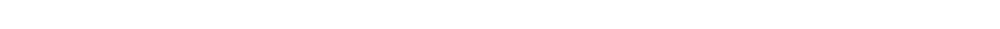

In [ ]:
import os
import gdown
import marimo as mo

train_json = "MultiRC/train_456-fixedIds.json"
test_json = "MultiRC/test_83-fixedIds.json"

if not (os.path.exists(train_json) and os.path.exists(test_json)):
    gdown.download_folder(id="18SlXjdkhUrG_PE0aTysMypMKx41a9evH")

In [ ]:
import json

with open(train_json, "r", encoding="utf-8") as f:
    train_data = json.load(f)["data"]

with open(test_json, "r", encoding="utf-8") as f:
    test_data = json.load(f)["data"]

print(train_data[1])

{'paragraph': {'text': '<b>Sent 1: </b>Before the mysterious disappearance of one of its passenger jets this month, Malaysia wasn\'t a country used to finding itself dominating headlines around the world.<br><b>Sent 2: </b>Some of its Southeast Asian neighbors, including Indonesia and the Philippines, have suffered devastating natural disasters in recent years and are all too familiar with the media frenzy that accompanies a major crisis.<br><b>Sent 3: </b>But Malaysia has largely managed to stay out of the international spotlight since its independence from British colonial rule more than half a century ago.<br><b>Sent 4: </b>"It is one of these countries, because of its geography, that doesn\'t have earthquakes," said Ernest Bower, senior adviser for Southeast Asia studies at the Center for Strategic and International Studies.<br><b>Sent 5: </b>"It doesn\'t have tsunamis.<br><b>Sent 6: </b>It hasn\'t been tested with a disaster like this."<br><b>Sent 7: </b>The disappearance of Malay

In [ ]:
import re

SENT_SEP = "\n"
_SENT_MARK_RE = re.compile(r"<b>\s*Sent\s*\d+\s*:\s*</b>", re.IGNORECASE)


def clean_sentence(text):
    return re.sub(r"<[^>]+>", " ", text).strip()


def split_sentences(text):
    sentences = []
    for part in _SENT_MARK_RE.split(text):
        cleaned = clean_sentence(part)
        if cleaned:
            sentences.append(cleaned)
    return sentences


def clean_passage(text):
    return SENT_SEP.join(split_sentences(text))


def flatten_data(data):
    flat = []
    for item in data:
        passage = clean_passage(item["paragraph"]["text"])
        for question_entry in item["paragraph"]["questions"]:
            question_text = question_entry["question"]
            for answer_entry in question_entry["answers"]:
                flat.append((
                    passage,
                    question_text,
                    answer_entry["text"],
                    answer_entry["isAnswer"],
                ))
    return flat

In [ ]:
import re

TOKEN_RE = re.compile(r"\w+")


def tokenize(text):
    return TOKEN_RE.findall(text.lower())


PAD_TOKEN = "<pad>"
SEP_TOKEN = "<sep>"
UNK_TOKEN = "<unk>"

In [ ]:
import multiprocessing
from collections import Counter

import torch
from torch.utils.data import DataLoader, Dataset


def build_vocab(flat_data, min_freq=MIN_FREQ):
    counter = Counter()
    for passage, question, answer, _ in flat_data:
        for sentence in passage.split(SENT_SEP):
            counter.update(tokenize(sentence))
        counter.update(tokenize(question))
        counter.update(tokenize(answer))

    vocab = {PAD_TOKEN: 0, SEP_TOKEN: 1, UNK_TOKEN: 2}
    for word, freq in counter.most_common():
        if freq >= min_freq:
            vocab[word] = len(vocab)
    return vocab


flat_train = flatten_data(train_data)
flat_test = flatten_data(test_data)

vocab = build_vocab(flat_train)
vocab_size = len(vocab)
PAD_ID = vocab[PAD_TOKEN]
SEP_ID = vocab[SEP_TOKEN]
UNK_ID = vocab[UNK_TOKEN]
print(f"Vocabulary size: {vocab_size}")


def encode_passage(passage, truncation=PASSAGE_TRUNCATION):
    ids = []
    for sentence in passage.split(SENT_SEP):
        ids.extend(vocab.get(t, UNK_ID) for t in tokenize(sentence))
        ids.append(SEP_ID)

    if len(ids) <= PASSAGE_MAX_TOKENS:
        return ids

    if truncation == "head":
        return ids[:PASSAGE_MAX_TOKENS]

    if truncation == "head_tail":
        tail_count = min(
            int(PASSAGE_MAX_TOKENS * PASSAGE_TAIL_FRACTION),
            PASSAGE_MAX_TOKENS,
        )
        head_count = PASSAGE_MAX_TOKENS - tail_count
        tail_part = ids[-tail_count:] if tail_count > 0 else []
        return ids[:head_count] + tail_part

    raise ValueError(f"Unknown truncation mode: {truncation!r} (expected 'head' or 'head_tail')")


def encode_qa(question, answer):
    question_tokens = tokenize(question)[:QUESTION_MAX_TOKENS]
    answer_tokens = tokenize(answer)[:ANSWER_MAX_TOKENS]
    tokens = question_tokens + [SEP_TOKEN] + answer_tokens + [SEP_TOKEN]
    token_ids = [vocab.get(token, UNK_ID) for token in tokens]
    return token_ids[:QA_MAX_TOKENS]


def pad_sequences(token_lists, pad_id=PAD_ID):
    max_len = max(len(ids) for ids in token_lists)
    padded = [list(ids) + [pad_id] * (max_len - len(ids)) for ids in token_lists]
    return torch.tensor(padded, dtype=torch.long)


def collate_batch(batch):
    passage_ids, qa_ids, targets, qids = zip(*batch)
    return (
        pad_sequences(passage_ids),
        pad_sequences(qa_ids),
        torch.stack(targets),
        torch.tensor(qids, dtype=torch.long),
    )


class MultiRCDataset(Dataset):
    def __init__(self, flat_data, truncation=PASSAGE_TRUNCATION):
        self.truncation = truncation
        self.items = []
        self.labels = []
        self.qids = []

        question_ids = {}
        for passage, question, answer, label in flat_data:
            key = (passage, question)
            if key not in question_ids:
                question_ids[key] = len(question_ids)
            qid = question_ids[key]

            passage_encoded = encode_passage(passage, truncation)
            qa_encoded = encode_qa(question, answer)
            target = torch.tensor(1.0 if label else 0.0, dtype=torch.float)

            self.items.append((passage_encoded, qa_encoded, target, qid))
            self.labels.append(bool(label))
            self.qids.append(qid)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]


class GroupedBatchSampler:
    def __init__(self, qids, batch_size, seed=SEED):
        self.batch_size = batch_size
        self.seed = seed
        self.epoch = 0
        self.groups = {}
        for index, qid in enumerate(qids):
            self.groups.setdefault(qid, []).append(index)

    def __iter__(self):
        keys = sorted(self.groups)
        generator = torch.Generator().manual_seed(self.seed + self.epoch)
        order = torch.randperm(len(keys), generator=generator).tolist()
        self.epoch += 1

        batch = []
        for key_idx in order:
            batch.extend(self.groups[keys[key_idx]])
            if len(batch) >= self.batch_size:
                yield batch
                batch = []

        if batch:
            yield batch

    def __len__(self):
        total_items = sum(len(group) for group in self.groups.values())
        return max(1, int(round(total_items / max(1, self.batch_size))))


# Passage-level train/validation split to prevent leakage across candidate answers
_passages = {}
for idx, example in enumerate(flat_train):
    _passages.setdefault(example[0], []).append(idx)

_passage_keys = sorted(_passages)
_generator = torch.Generator().manual_seed(SEED)
_order = torch.randperm(len(_passage_keys), generator=_generator).tolist()
_passage_keys = [_passage_keys[i] for i in _order]

_val_count = int(VAL_FRACTION * len(_passage_keys))
_val_keys = set(_passage_keys[:_val_count])

_train_examples = []
_val_examples = []
for passage_key in _passage_keys:
    target_list = _val_examples if passage_key in _val_keys else _train_examples
    for example_idx in _passages[passage_key]:
        target_list.append(flat_train[example_idx])

_WORKER_NOTICE_SHOWN = [False]


def _loader_workers(num_workers=NUM_WORKERS):
    if not num_workers:
        return 0

    defined_in_cell = (
        MultiRCDataset.__module__ == "__main__"
        or collate_batch.__module__ == "__main__"
    )
    if defined_in_cell and multiprocessing.get_start_method() != "fork":
        if not _WORKER_NOTICE_SHOWN[0]:
            _WORKER_NOTICE_SHOWN[0] = True
            print(
                f"NOTE: NUM_WORKERS={num_workers} falling back to 0 (in-process) "
                f"to support notebook-scoped dataset under {multiprocessing.get_start_method()!r}."
            )
        return 0

    return num_workers


def build_loaders(truncation=PASSAGE_TRUNCATION):
    train_ds = MultiRCDataset(_train_examples, truncation)
    val_ds = MultiRCDataset(_val_examples, truncation)
    test_ds = MultiRCDataset(flat_test, truncation)

    workers = _loader_workers()
    loader_kwargs = {
        "num_workers": workers,
        "pin_memory": torch.cuda.is_available(),
        "persistent_workers": workers > 0,
    }

    if GROUPED_BATCHES:
        train_sampler = GroupedBatchSampler(train_ds.qids, BATCH_SIZE)
        train_loader = DataLoader(
            train_ds,
            batch_sampler=train_sampler,
            collate_fn=collate_batch,
            **loader_kwargs,
        )
    else:
        train_loader = DataLoader(
            train_ds,
            batch_size=BATCH_SIZE,
            shuffle=True,
            collate_fn=collate_batch,
            **loader_kwargs,
        )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_batch,
        **loader_kwargs,
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_batch,
        **loader_kwargs,
    )

    return train_ds, val_ds, test_ds, train_loader, val_loader, test_loader


train_dataset, val_dataset, test_dataset, train_loader, val_loader, test_loader = build_loaders()

print(
    f"Tuples: {len(train_dataset)} train / {len(val_dataset)} val / {len(test_dataset)} test | "
    f"DataLoader workers: {train_loader.num_workers}"
)

_train_pos = sum(train_dataset.labels)
_train_neg = len(train_dataset.labels) - _train_pos
POS_WEIGHT = torch.tensor(_train_neg / max(_train_pos, 1), dtype=torch.float)

print(
    f"Train positives: {_train_pos:,}/{len(train_dataset.labels):,} "
    f"({_train_pos / len(train_dataset.labels):.1%}) -> "
    f"POS_WEIGHT = {POS_WEIGHT.item():.4f}"
)

Vocabulary size: 17343
Tuples: 22926 train / 4317 val / 4848 test | DataLoader workers: 0
Train positives: 10,108/22,926 (44.1%) -> POS_WEIGHT = 1.2681


## Tokenization & Encoding

A word-level tokenizer: a regex takes lowercase word tokens and drops punctuation
(stop words are kept -- see the `tokenizer` cell), and the vocabulary is built from
the training tuples (`MIN_FREQ` drops rare words). Each
example feeds up to **two** encoder inputs:

```
sentence <sep> sentence <sep> ...   -> passage tower
question <sep> answer <sep>         -> question/answer tower
```

MultiRC pairs each passage with several questions, and each question with several
candidate answers. The passage is segmented into sentences, so the `<sep>` between
sentences preserves the multi-sentence structure the task is built around: the
evidence for an answer usually sits in one or two specific sentences. Splitting the
passage from the question+answer also keeps the question/answer on a short, direct
gradient path instead of burying it at the end of one long
`passage <sep> question <sep> answer` sequence, and gives attention two distinct
representations to relate. There is deliberately no `[CLS]` token -- a BiGRU does
not need one, and the classifier aggregates each tower itself (see the pooling
options below).

The two `<sep>` markers in the question/answer tower also delimit the answer span,
which the head pools over (`QA_POOLING`). Each tower is capped separately
(`PASSAGE_MAX_TOKENS`, `QA_MAX_TOKENS`) and batches are padded only to the longest
sequence *in that batch*; padded timesteps are packed out of the BiGRUs and masked
out of attention and pooling. The `single` encoder instead concatenates the two into
`passage <sep> question <sep> answer` for one BiGRU -- the ablation baseline for the
two-tower split.

# 2. Model Implementation
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

In [ ]:
import math
import torch
import torch.nn as nn


class SelfAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

        self.capture_attention = False
        self.last_weights = None

    def forward(self, x, mask=None):
        batch_size, seq_len, _ = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)

        q = q.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(mask[:, None, None, :], -1e9)

        weights = self.dropout(scores.softmax(dim=-1))
        if self.capture_attention:
            self.last_weights = weights.detach()

        context = (weights @ v).transpose(1, 2).reshape(batch_size, seq_len, -1)
        return self.out(context)


class CrossAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.out = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

        self.capture_attention = False
        self.last_weights = None

    def forward(self, query, key_value, key_mask=None):
        batch_size, q_len, _ = query.shape
        kv_len = key_value.size(1)

        q = self.W_q(query).view(batch_size, q_len, self.num_heads, self.d_k).transpose(1, 2)
        k = self.W_k(key_value).view(batch_size, kv_len, self.num_heads, self.d_k).transpose(1, 2)
        v = self.W_v(key_value).view(batch_size, kv_len, self.num_heads, self.d_k).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_k)
        if key_mask is not None:
            scores = scores.masked_fill(key_mask[:, None, None, :], -1e9)

        weights = self.dropout(scores.softmax(dim=-1))
        if self.capture_attention:
            self.last_weights = weights.detach()

        context = (weights @ v).transpose(1, 2).reshape(batch_size, q_len, -1)
        return self.out(context)


class InterAttention(nn.Module):
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.W = nn.Linear(d_model, d_model, bias=False)
        self.passage_out = nn.Linear(4 * d_model, d_model)
        self.qa_out = nn.Linear(4 * d_model, d_model)
        self.dropout = nn.Dropout(dropout)

        self.capture_attention = False
        self.last_weights = None

    def forward(self, qa, passage, qa_mask, passage_mask):
        similarity = torch.bmm(self.W(qa), passage.transpose(1, 2)) / math.sqrt(qa.size(-1))
        similarity = similarity.masked_fill(qa_mask[:, :, None], -1e9)
        similarity = similarity.masked_fill(passage_mask[:, None, :], -1e9)

        qa_to_passage = similarity.softmax(dim=-1)
        if self.capture_attention:
            self.last_weights = qa_to_passage.detach()

        passage_to_qa = similarity.transpose(1, 2).softmax(dim=-1)
        passage_align = torch.bmm(qa_to_passage, passage)
        qa_align = torch.bmm(passage_to_qa, qa)

        passage_diff = (passage - qa_align).abs()
        passage_prod = passage * qa_align
        passage_enhanced = torch.cat([passage, qa_align, passage_diff, passage_prod], dim=-1)
        passage = passage + self.dropout(self.passage_out(passage_enhanced))

        qa_diff = (qa - passage_align).abs()
        qa_prod = qa * passage_align
        qa_enhanced = torch.cat([qa, passage_align, qa_diff, qa_prod], dim=-1)
        qa = qa + self.dropout(self.qa_out(qa_enhanced))

        return qa, passage

In [ ]:
import torch
import torch.nn as nn


def run_bigru(gru, x, mask):
    lengths = (~mask).sum(dim=1).clamp(min=1).cpu()
    packed = nn.utils.rnn.pack_padded_sequence(
        x, lengths, batch_first=True, enforce_sorted=False
    )
    packed_out, h_n = gru(packed)
    out, _ = nn.utils.rnn.pad_packed_sequence(
        packed_out, batch_first=True, total_length=x.size(1)
    )
    return out, h_n


def masked_mean(x, mask):
    keep = (~mask).unsqueeze(-1).float()
    return (x * keep).sum(dim=1) / keep.sum(dim=1).clamp(min=1)


def masked_max(x, mask):
    return x.masked_fill(mask.unsqueeze(-1), -1e9).max(dim=1).values


class AttentionPooling(nn.Module):
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.Tanh(),
            nn.Linear(d_model, 1),
        )
        self.dropout = nn.Dropout(dropout)
        self.capture_attention = False
        self.last_weights = None

    def forward(self, x, mask):
        scores = self.score(x).squeeze(-1)
        scores = scores.masked_fill(mask, -1e9)
        weights = self.dropout(scores.softmax(dim=-1))

        if self.capture_attention:
            self.last_weights = weights.detach()

        return (weights.unsqueeze(-1) * x).sum(dim=1)


POOLINGS = ("final", "mean", "max", "attention")
ENCODERS = ("two_tower", "single")
PASSAGE_ENCODERS = ("bigru", "none")
CROSS_DIRECTIONS = ("both", "qa_to_passage")
ATTENTIONS = ("self", "cross", "inter", "none")
HEADS = ("concat", "interaction", "compare", "match")
MATCH_FEATURE_DIM = 6


def pool_sequence(x, h_n, mask, pooling, attn_pool=None):
    if pooling == "final":
        return torch.cat([h_n[-2], h_n[-1]], dim=-1)
    if pooling == "mean":
        return masked_mean(x, mask)
    if pooling == "max":
        return masked_max(x, mask)
    if pooling == "attention":
        return attn_pool(x, mask)
    raise ValueError(f"Unknown pooling: {pooling!r} (expected one of {POOLINGS})")


def answer_padding_mask(qa_ids):
    seq_len = qa_ids.size(1)
    idx = torch.arange(seq_len, device=qa_ids.device).expand_as(qa_ids)
    is_sep = qa_ids == SEP_ID
    sentinel = torch.full_like(idx, seq_len)

    first_sep = torch.where(is_sep, idx, sentinel).min(dim=1).values
    second_sep = torch.where(
        is_sep & (idx > first_sep[:, None]), idx, sentinel
    ).min(dim=1).values

    is_answer = (idx > first_sep[:, None]) & (idx < second_sep[:, None])
    return ~is_answer


def joint_sequence(passage_ids, qa_ids):
    combined = torch.cat([passage_ids, qa_ids], dim=1)
    order = (combined == PAD_ID).argsort(dim=1, stable=True)
    return combined.gather(1, order)


def _head_input(passage_vec, qa_vec, head):
    if head == "interaction":
        diff = (passage_vec - qa_vec).abs()
        prod = passage_vec * qa_vec
        return torch.cat([passage_vec, qa_vec, diff, prod], dim=-1)

    if head == "compare":
        diff = (passage_vec - qa_vec).abs()
        prod = passage_vec * qa_vec
        return torch.cat([diff, prod], dim=-1)

    return torch.cat([passage_vec, qa_vec], dim=-1)


def _passage_match_features(
    passage_ids,
    qa_ids,
    passage_mask,
    embedding,
    match_w,
    qa_states=None,
    passage_states=None,
    state_query=None,
    state_key=None,
    scale=1.0,
):
    answer_mask = answer_padding_mask(qa_ids)
    keep_passage = (passage_ids != PAD_ID) & (passage_ids != UNK_ID)
    answer_tokens = ~answer_mask & (qa_ids != PAD_ID) & (qa_ids != UNK_ID)

    present = (
        (qa_ids[:, :, None] == passage_ids[:, None, :])
        & keep_passage[:, None, :]
        & answer_tokens[:, :, None]
    ).any(dim=-1)

    n_answer = (~answer_mask & (qa_ids != PAD_ID)).sum(dim=1).clamp(min=1)
    n_passage = keep_passage.sum(dim=1).clamp(min=1)

    norm_qa_emb = nn.functional.normalize(embedding(qa_ids), dim=-1)
    norm_passage_emb = nn.functional.normalize(embedding(passage_ids), dim=-1)
    similarity = torch.bmm(match_w(norm_qa_emb), norm_passage_emb.transpose(1, 2))
    similarity = similarity.masked_fill(passage_mask[:, None, :], -1e9)

    per_answer = similarity.max(dim=-1).values
    best = per_answer.masked_fill(answer_mask, -1e9).max(dim=1).values
    best = torch.where((~answer_mask).any(dim=1), best, torch.zeros_like(best))
    mean_best = (per_answer * (~answer_mask)).sum(dim=1) / (~answer_mask).sum(dim=1).clamp(min=1)

    features = [
        present.sum(dim=1).float() / n_answer,
        present.sum(dim=1).float() / n_passage,
        best,
        mean_best,
    ]

    if qa_states is None:
        zero = torch.zeros_like(best)
        return torch.cat(
            [torch.stack(features, dim=-1), zero.unsqueeze(-1), zero.unsqueeze(-1)],
            dim=-1,
        )

    query_proj = torch.tanh(state_query(qa_states))
    key_proj = torch.tanh(state_key(passage_states)).transpose(1, 2)
    state_sim = torch.bmm(query_proj, key_proj) / scale
    state_sim = state_sim.masked_fill(passage_mask[:, None, :], -1e9)

    per_state = state_sim.max(dim=-1).values
    best_state = per_state.masked_fill(answer_mask, -1e9).max(dim=1).values
    best_state = torch.where(
        (~answer_mask).any(dim=1), best_state, torch.zeros_like(best_state)
    )
    mean_state = (per_state * (~answer_mask)).sum(dim=1) / (~answer_mask).sum(dim=1).clamp(min=1)

    return torch.cat(
        [
            torch.stack(features, dim=-1),
            best_state.unsqueeze(-1),
            mean_state.unsqueeze(-1),
        ],
        dim=-1,
    )


class BiGRUClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=128,
        num_heads=4,
        num_layers=1,
        encoder="two_tower",
        attention="cross",
        pooling="mean",
        qa_pooling="answer",
        passage_encoder="bigru",
        cross_direction="both",
        head="concat",
        dropout=0.2,
        match_features=False,
    ):
        super().__init__()
        if encoder not in ENCODERS:
            raise ValueError(f"Unknown encoder: {encoder!r} (expected one of {ENCODERS})")
        if attention not in ATTENTIONS:
            raise ValueError(f"Unknown attention: {attention!r} (expected one of {ATTENTIONS})")
        if passage_encoder not in PASSAGE_ENCODERS:
            raise ValueError(
                f"Unknown passage_encoder: {passage_encoder!r} (expected one of {PASSAGE_ENCODERS})"
            )
        if head not in HEADS:
            raise ValueError(f"Unknown head: {head!r} (expected one of {HEADS})")
        if head == "match" and not match_features:
            raise ValueError("head='match' requires match_features=True")
        if cross_direction not in CROSS_DIRECTIONS:
            raise ValueError(
                f"Unknown cross_direction: {cross_direction!r} (expected one of {CROSS_DIRECTIONS})"
            )
        if encoder == "single" and attention in ("cross", "inter"):
            raise ValueError(
                "encoder='single' has one tower; use attention='self' or 'none'"
            )
        if encoder == "two_tower" and passage_encoder == "none" and pooling == "final":
            raise ValueError(
                "pooling='final' requires passage_encoder='bigru'"
            )

        self.encoder_name = encoder
        self.attention_name = attention
        self.pooling_name = pooling
        self.qa_pooling = qa_pooling
        self.passage_encoder_name = passage_encoder
        self.cross_direction = cross_direction
        self.head_name = head

        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.emb_dropout = nn.Dropout(dropout)

        self.match_features = bool(match_features)
        self.match_w = nn.Linear(d_model, d_model, bias=False) if self.match_features else None
        self.match_state_q = nn.Linear(d_model, d_model) if self.match_features else None
        self.match_state_k = nn.Linear(d_model, d_model) if self.match_features else None
        self.match_scale = float(d_model) ** 0.5
        if self.match_w is not None:
            with torch.no_grad():
                self.match_w.weight.copy_(torch.eye(d_model))

        gru_dropout = dropout if num_layers > 1 else 0.0

        self.inter = None
        if encoder == "two_tower":
            self.passage_gru = (
                nn.GRU(
                    d_model,
                    d_model // 2,
                    num_layers=num_layers,
                    batch_first=True,
                    bidirectional=True,
                    dropout=gru_dropout,
                )
                if passage_encoder == "bigru"
                else None
            )
            self.qa_gru = nn.GRU(
                d_model,
                d_model // 2,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=True,
                dropout=gru_dropout,
            )
            self.passage_norm = nn.LayerNorm(d_model)
            self.qa_norm = nn.LayerNorm(d_model)

            self.passage_self_attn = (
                SelfAttention(d_model, num_heads, dropout) if attention == "self" else None
            )
            self.qa_self_attn = (
                SelfAttention(d_model, num_heads, dropout) if attention == "self" else None
            )
            self.passage_to_qa = (
                CrossAttention(d_model, num_heads, dropout)
                if attention == "cross" and cross_direction == "both"
                else None
            )
            self.qa_to_passage = (
                CrossAttention(d_model, num_heads, dropout) if attention == "cross" else None
            )
            self.inter = (
                InterAttention(d_model, dropout) if attention == "inter" else None
            )

            self.passage_pool = (
                AttentionPooling(d_model, dropout) if pooling == "attention" else None
            )
            self.qa_pool = (
                AttentionPooling(d_model, dropout) if pooling == "attention" else None
            )

            if head == "match":
                head_in = MATCH_FEATURE_DIM
            else:
                head_in = 4 * d_model if head == "interaction" else 2 * d_model
                if self.match_features:
                    head_in += MATCH_FEATURE_DIM
        else:
            self.joint_gru = nn.GRU(
                d_model,
                d_model // 2,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=True,
                dropout=gru_dropout,
            )
            self.joint_norm = nn.LayerNorm(d_model)
            self.joint_self_attn = (
                SelfAttention(d_model, num_heads, dropout) if attention == "self" else None
            )
            self.joint_pool = (
                AttentionPooling(d_model, dropout) if pooling == "attention" else None
            )
            head_in = d_model + (MATCH_FEATURE_DIM if self.match_features else 0)

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(head_in, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, 1),
        )

    def forward(self, passage_ids, qa_ids):
        if self.encoder_name == "single":
            return self._forward_single(passage_ids, qa_ids)
        return self._forward_two_tower(passage_ids, qa_ids)

    def _forward_two_tower(self, passage_ids, qa_ids):
        passage_mask = passage_ids == PAD_ID
        qa_mask = qa_ids == PAD_ID

        passage_emb = self.emb_dropout(self.embedding(passage_ids))
        if self.passage_gru is not None:
            passage, passage_h = run_bigru(self.passage_gru, passage_emb, passage_mask)
        else:
            passage, passage_h = passage_emb, None
        passage = self.dropout(passage)

        qa, qa_h = run_bigru(
            self.qa_gru, self.emb_dropout(self.embedding(qa_ids)), qa_mask
        )
        qa = self.dropout(qa)

        if self.passage_self_attn is not None:
            passage = passage + self.dropout(
                self.passage_self_attn(self.passage_norm(passage), passage_mask)
            )
            qa = qa + self.dropout(self.qa_self_attn(self.qa_norm(qa), qa_mask))
        elif self.inter is not None:
            qa, passage = self.inter(
                self.qa_norm(qa), self.passage_norm(passage), qa_mask, passage_mask
            )
        elif self.qa_to_passage is not None:
            p_norm = self.passage_norm(passage)
            q_norm = self.qa_norm(qa)
            if self.passage_to_qa is not None:
                passage = passage + self.dropout(
                    self.passage_to_qa(p_norm, q_norm, key_mask=qa_mask)
                )
            qa = qa + self.dropout(
                self.qa_to_passage(q_norm, p_norm, key_mask=passage_mask)
            )

        qa_pool_mask = (
            answer_padding_mask(qa_ids) if self.qa_pooling == "answer" else qa_mask
        )
        passage_vec = pool_sequence(
            passage, passage_h, passage_mask, self.pooling_name, self.passage_pool
        )
        qa_vec = pool_sequence(qa, qa_h, qa_pool_mask, self.pooling_name, self.qa_pool)

        if self.match_features:
            match_feats = _passage_match_features(
                passage_ids,
                qa_ids,
                passage_mask,
                self.embedding,
                self.match_w,
                qa_states=qa,
                passage_states=passage,
                state_query=self.match_state_q,
                state_key=self.match_state_k,
                scale=self.match_scale,
            )
            if self.head_name == "match":
                pooled = match_feats
            else:
                head_reps = _head_input(passage_vec, qa_vec, self.head_name)
                pooled = torch.cat([head_reps, match_feats], dim=-1)
        else:
            pooled = _head_input(passage_vec, qa_vec, self.head_name)

        logits = self.classifier(self.dropout(pooled)).squeeze(-1)
        return logits

    def _forward_single(self, passage_ids, qa_ids):
        ids = joint_sequence(passage_ids, qa_ids)
        mask = ids == PAD_ID

        states, h_n = run_bigru(
            self.joint_gru, self.emb_dropout(self.embedding(ids)), mask
        )
        states = self.dropout(states)

        if self.joint_self_attn is not None:
            states = states + self.dropout(
                self.joint_self_attn(self.joint_norm(states), mask)
            )

        pooled = pool_sequence(states, h_n, mask, self.pooling_name, self.joint_pool)
        if self.match_features:
            match_feats = _passage_match_features(
                passage_ids,
                qa_ids,
                passage_ids == PAD_ID,
                self.embedding,
                self.match_w,
            )
            pooled = torch.cat([pooled, match_feats], dim=-1)

        logits = self.classifier(self.dropout(pooled)).squeeze(-1)
        return logits

In [ ]:
import math
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    roc_auc_score,
)
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

if DEVICE.type == "cuda" and USE_TF32:
    try:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        print("TF32 enabled for matmul + cuDNN")
    except Exception as exc:
        print(f"TF32 not available: {type(exc).__name__}: {exc}")


def per_question_metrics(qids, labels, preds, scores=None):
    groups = {}
    for qid, gold, pred in zip(qids, labels, preds):
        groups.setdefault(qid, []).append((gold, pred))

    score_groups = {}
    if scores is not None:
        for qid, gold, score in zip(qids, labels, scores):
            score_groups.setdefault(qid, []).append((gold, score))

    em_total = 0.0
    f1_total = 0.0

    for rows in groups.values():
        all_match = all(gold == pred for gold, pred in rows)
        em_total += float(all_match)

        gold_indices = {i for i, (gold, _) in enumerate(rows) if gold == 1}
        pred_indices = {i for i, (_, pred) in enumerate(rows) if pred == 1}

        if not gold_indices and not pred_indices:
            f1_total += 1.0
        elif gold_indices and pred_indices:
            intersection_size = len(gold_indices & pred_indices)
            total_size = len(gold_indices) + len(pred_indices)
            f1_total += 2 * intersection_size / total_size

    n_questions = max(len(groups), 1)
    out = {
        "q_em": em_total / n_questions,
        "q_f1": f1_total / n_questions,
        "n_questions": len(groups),
    }

    if scores is not None:
        auc_by_question = {}
        ap_by_question = {}

        for qid, rows in score_groups.items():
            gold_vec = [gold for gold, _ in rows]
            score_vec = [score for _, score in rows]

            if len(set(gold_vec)) < 2:
                continue

            auc_by_question[qid] = roc_auc_score(gold_vec, score_vec)
            ap_by_question[qid] = average_precision_score(gold_vec, score_vec)

        aucs = list(auc_by_question.values())
        aps = list(ap_by_question.values())

        out["q_auc"] = sum(aucs) / len(aucs) if aucs else 0.5
        out["q_ap"] = sum(aps) / len(aps) if aps else 0.0
        out["n_questions_ranked"] = len(aucs)
        out["q_auc_by_question"] = auc_by_question
        out["q_ap_by_question"] = ap_by_question

    return out


def evaluate(model, data_loader, threshold=0.5, rule=THRESHOLD_RULE):
    model.eval()
    criterion = nn.BCEWithLogitsLoss()

    all_logits = []
    all_labels = []
    all_qids = []
    total_loss = 0.0
    num_batches = 0

    with torch.no_grad():
        for passage_ids, qa_ids, targets, batch_qids in data_loader:
            passage_ids = passage_ids.to(DEVICE, non_blocking=True)
            qa_ids = qa_ids.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            logits = model(passage_ids, qa_ids)
            total_loss = total_loss + criterion(logits, targets).detach()
            num_batches += 1

            all_logits.append(logits.detach())
            all_labels.append(targets.detach())
            all_qids.append(batch_qids)

    scores = []
    labels = []
    qids = []
    if all_logits:
        scores = torch.sigmoid(torch.cat(all_logits)).cpu().tolist()
        labels = torch.cat(all_labels).long().cpu().tolist()
        qids = torch.cat(all_qids).tolist()

    transformed_scores = decision_scores(scores, qids, rule)
    preds = [int(s > threshold) for s in transformed_scores]

    metrics = {
        "loss": float(total_loss / max(num_batches, 1)),
        "rule": rule,
        "acc": accuracy_score(labels, preds),
        "yes_rate": sum(preds) / max(len(preds), 1),
        "f1": f1_score(labels, preds, zero_division=0),
        "auc": roc_auc_score(labels, scores) if len(set(labels)) > 1 else 0.5,
        "ap": average_precision_score(labels, scores) if len(set(labels)) > 1 else 0.0,
        "labels": labels,
        "scores": scores,
        "qids": qids,
    }
    metrics.update(per_question_metrics(qids, labels, preds, scores))
    return metrics


def predicted_positive_rate(scores, threshold):
    if not scores:
        return 0.0
    return sum(1 for s in scores if s > threshold) / len(scores)


def centre_within_question(scores, qids):
    totals = {}
    counts = {}
    for qid, score in zip(qids, scores):
        totals[qid] = totals.get(qid, 0.0) + score
        counts[qid] = counts.get(qid, 0) + 1

    return [score - totals[qid] / counts[qid] for score, qid in zip(scores, qids)]


def decision_scores(scores, qids, rule=THRESHOLD_RULE):
    if rule == "within_question":
        if qids is None:
            raise ValueError(
                "THRESHOLD_RULE='within_question' requires question IDs for centring"
            )
        return centre_within_question(scores, qids)
    return list(scores)


def declared_threshold(
    labels, scores, qids=None, rule=THRESHOLD_RULE, fixed=THRESHOLD_FIXED
):
    if rule == "fixed":
        return float(fixed)

    if rule not in ("prior_match", "within_question"):
        raise ValueError(
            f"Unknown threshold rule: {rule!r} (expected 'within_question', 'prior_match', or 'fixed')"
        )

    decision_vals = decision_scores(scores, qids, rule)
    target_rate = float(sum(labels)) / max(len(labels), 1)
    descending = sorted(decision_vals, reverse=True)
    rank_idx = min(int(round(target_rate * len(descending))), len(descending) - 1)
    return float(descending[rank_idx])


def sweep_threshold(
    qids,
    labels,
    scores,
    metric=THRESHOLD_METRIC,
    lo=THRESHOLD_MIN,
    hi=THRESHOLD_MAX,
    step=THRESHOLD_STEP,
):
    n_steps = int(round((hi - lo) / step))
    grid = [lo + i * step for i in range(n_steps + 1)]
    values = []

    for t in grid:
        preds = [int(s > t) for s in scores]
        if metric == "q_f1":
            values.append(per_question_metrics(qids, labels, preds)["q_f1"])
        else:
            values.append(f1_score(labels, preds, zero_division=0))

    best_idx = max(range(len(grid)), key=lambda i: values[i])
    return float(grid[best_idx]), float(values[best_idx])


LOSSES = ("bce", "within_question")
LOSS_TAGS = {"bce": "bce", "within_question": "wq"}
HEAD_TAGS = {"concat": "cc", "interaction": "ix", "compare": "cmp", "match": "mt"}


def variant_tag(head=HEAD, loss=LOSS):
    head_tag = HEAD_TAGS.get(head, head)
    loss_tag = LOSS_TAGS.get(loss, loss)
    return f"{head_tag}+{loss_tag}"


def run_label(encoder, attention, pooling, seed=None, variant=None):
    key = f"{encoder}/{attention}/{pooling}"
    if variant:
        key = f"{key}/{variant}"
    return key if seed is None else f"{key}/s{seed}"


def create_model(
    encoder=ENCODER,
    attention=ATTENTION,
    pooling=POOLING,
    qa_pooling=QA_POOLING,
    passage_encoder=PASSAGE_ENCODER,
    cross_direction=CROSS_DIRECTION,
    head=HEAD,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    match_features=MATCH_FEATURES,
    seed=SEED,
):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    return BiGRUClassifier(
        vocab_size=vocab_size,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers,
        encoder=encoder,
        attention=attention,
        pooling=pooling,
        qa_pooling=qa_pooling,
        passage_encoder=passage_encoder,
        cross_direction=cross_direction,
        head=head,
        dropout=dropout,
        match_features=match_features,
    ).to(DEVICE)


def lr_for_epoch(
    epoch,
    num_epochs,
    base_lr=LR,
    warmup_epochs=LR_WARMUP_EPOCHS,
    decay=LR_DECAY,
    min_lr=LR_MIN,
):
    if warmup_epochs and epoch < warmup_epochs:
        return base_lr * (epoch + 1) / warmup_epochs

    if decay == "cosine":
        span = max(1, num_epochs - warmup_epochs)
        progress = min(1.0, (epoch - warmup_epochs) / span)
        return min_lr + 0.5 * (base_lr - min_lr) * (1 + math.cos(math.pi * progress))

    return base_lr


def within_question_loss(
    logits, targets, qids, pairwise_weight=PAIRWISE_WEIGHT, pos_weight=None
):
    unique_qids, inverse_indices = torch.unique(qids, return_inverse=True)
    n_groups = len(unique_qids)

    totals = torch.zeros(n_groups, device=logits.device, dtype=logits.dtype)
    counts = torch.zeros(n_groups, device=logits.device, dtype=logits.dtype)
    totals = totals.index_add(0, inverse_indices, logits)
    counts = counts.index_add(0, inverse_indices, torch.ones_like(logits))

    group_means = totals / counts.clamp(min=1.0)
    centred_logits = logits - group_means[inverse_indices]

    bce_loss = nn.functional.binary_cross_entropy_with_logits(
        centred_logits, targets, pos_weight=pos_weight
    )

    if not pairwise_weight or n_groups < 2:
        return bce_loss

    ranking_loss = None
    pairs_count = 0

    for group_idx in range(n_groups):
        mask = inverse_indices == group_idx
        pos_scores = centred_logits[mask & (targets > 0.5)]
        neg_scores = centred_logits[mask & (targets <= 0.5)]

        if pos_scores.numel() > 0 and neg_scores.numel() > 0:
            diff = -(pos_scores[:, None] - neg_scores[None, :])
            term = nn.functional.softplus(diff).mean()
            ranking_loss = term if ranking_loss is None else ranking_loss + term
            pairs_count += 1

    if pairs_count > 0:
        bce_loss = bce_loss + pairwise_weight * (ranking_loss / pairs_count)

    return bce_loss


def train_model(
    model,
    train_loader,
    val_loader,
    num_epochs=NUM_EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    label="model",
    seed=SEED,
    use_class_weights=USE_CLASS_WEIGHTS,
    early_stopping=EARLY_STOPPING,
    early_stop_patience=EARLY_STOP_PATIENCE,
    early_stop_min_delta=EARLY_STOP_MIN_DELTA,
    early_stop_metric=EARLY_STOP_METRIC,
    early_stop_min_epochs=EARLY_STOP_MIN_EPOCHS,
    loss=LOSS,
    pairwise_weight=PAIRWISE_WEIGHT,
):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    decay_params = []
    no_decay_params = []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim == 1 or name.startswith("embedding"):
            no_decay_params.append(param)
        else:
            decay_params.append(param)

    optimizer = optim.AdamW(
        [
            {"params": decay_params, "weight_decay": weight_decay},
            {"params": no_decay_params, "weight_decay": 0.0},
        ],
        lr=lr,
    )

    if loss not in LOSSES:
        raise ValueError(f"Unknown loss: {loss!r} (expected one of {LOSSES})")

    pos_weight = POS_WEIGHT.to(DEVICE) if use_class_weights else None
    criterion = (
        None
        if loss == "within_question"
        else nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    )

    metric_key = (
        early_stop_metric
        if early_stop_metric.startswith("val_")
        else f"val_{early_stop_metric}"
    )
    higher_is_better = metric_key != "val_loss"

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": [],
        "val_auc": [],
        "val_ap": [],
        "val_q_em": [],
        "val_q_f1": [],
        "val_q_auc": [],
        "val_q_ap": [],
        "lr": [],
        "val_q_f1_declared": [],
        "best_epoch": None,
        "best_score": None,
        "best_val_ap": None,
        "best_val_q_f1": None,
        "best_val_auc": None,
        "best_val_f1": None,
        "best_val_q_auc": None,
        "best_val_q_ap": None,
        "best_val_q_f1_declared": None,
        "stopped_epoch": None,
        "epochs_run": None,
        "budget": num_epochs,
        "early_stopping": bool(early_stopping),
        "loss_name": loss,
        "pairwise_weight": pairwise_weight,
        "threshold": 0.5,
        "threshold_score": None,
        "threshold_q_f1": None,
        "threshold_rule": None,
        "threshold_yes_rate": None,
        "sweep_threshold": None,
        "sweep_score": None,
        "sweep_yes_rate": None,
        "truncation": None,
        "config": None,
        "seed": seed,
    }

    best_score = -float("inf") if higher_is_better else float("inf")
    best_state = None
    epochs_without_improvement = 0

    def check_improved(current_score):
        if higher_is_better:
            return current_score > best_score + early_stop_min_delta
        return current_score < best_score - early_stop_min_delta

    for epoch in range(num_epochs):
        current_lr = lr_for_epoch(epoch, num_epochs)
        for param_group in optimizer.param_groups:
            param_group["lr"] = current_lr

        model.train()
        total_loss = 0.0
        num_batches = 0
        pbar = tqdm(
            train_loader,
            desc=f"[{label}] epoch {epoch+1}/{num_epochs}",
            leave=False,
        )

        for passage_ids, qa_ids, targets, batch_qids in pbar:
            passage_ids = passage_ids.to(DEVICE, non_blocking=True)
            qa_ids = qa_ids.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            batch_qids = batch_qids.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            logits = model(passage_ids, qa_ids)

            if criterion is None:
                batch_loss = within_question_loss(
                    logits, targets, batch_qids, pairwise_weight, pos_weight
                )
            else:
                batch_loss = criterion(logits, targets)

            batch_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()

            total_loss = total_loss + batch_loss.detach()
            num_batches += 1
            if num_batches % 20 == 0:
                pbar.set_postfix(loss=f"{batch_loss.item():.4f}")

        train_loss = float(total_loss / max(num_batches, 1))
        val_metrics = evaluate(model, val_loader, rule="prior_match")

        val_cut = declared_threshold(
            val_metrics["labels"], val_metrics["scores"], val_metrics["qids"]
        )
        val_decision_scores = decision_scores(
            val_metrics["scores"], val_metrics["qids"], THRESHOLD_RULE
        )
        declared_preds = [int(s > val_cut) for s in val_decision_scores]
        val_metrics["q_f1_declared"] = per_question_metrics(
            val_metrics["qids"], val_metrics["labels"], declared_preds
        )["q_f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_acc"].append(val_metrics["acc"])
        history["val_f1"].append(val_metrics["f1"])
        history["val_auc"].append(val_metrics["auc"])
        history["val_ap"].append(val_metrics["ap"])
        history["val_q_em"].append(val_metrics["q_em"])
        history["val_q_f1"].append(val_metrics["q_f1"])
        history["val_q_auc"].append(val_metrics["q_auc"])
        history["val_q_ap"].append(val_metrics["q_ap"])
        history["val_q_f1_declared"].append(val_metrics["q_f1_declared"])
        history["lr"].append(current_lr)

        print(
            f"[{label}] epoch {epoch+1}: train_loss={train_loss:.4f} "
            f"val_loss={val_metrics['loss']:.4f} val_ap={val_metrics['ap']:.4f} "
            f"val_q_f1={val_metrics['q_f1']:.4f} val_auc={val_metrics['auc']:.4f} "
            f"q_f1@declared={val_metrics['q_f1_declared']:.4f} "
            f"lr={current_lr:.2e}"
        )

        current_score = val_metrics[metric_key[4:]]
        if check_improved(current_score):
            best_score = current_score
            history["best_epoch"] = epoch + 1
            history["best_score"] = current_score
            history["best_val_ap"] = val_metrics["ap"]
            history["best_val_q_f1"] = val_metrics["q_f1"]
            history["best_val_auc"] = val_metrics["auc"]
            history["best_val_f1"] = val_metrics["f1"]
            history["best_val_q_auc"] = val_metrics["q_auc"]
            history["best_val_q_ap"] = val_metrics["q_ap"]
            history["best_val_q_f1_declared"] = val_metrics["q_f1_declared"]
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (
            early_stopping
            and epochs_without_improvement >= early_stop_patience
            and epoch + 1 >= early_stop_min_epochs
        ):
            history["stopped_epoch"] = epoch + 1
            print(
                f"[{label}] early stopping at epoch {epoch+1}: no {metric_key} "
                f"improvement for {early_stop_patience} epochs "
                f"(best epoch {history['best_epoch']})"
            )
            break

    history["epochs_run"] = len(history["train_loss"])

    if best_state is not None:
        model.load_state_dict(best_state)

    if early_stopping and history["stopped_epoch"] is None:
        print(
            f"[{label}] WARNING: the stopping rule never fired -- the run used "
            f"the whole budget ({num_epochs} epochs), so the last epoch was "
            f"reported rather than a chosen one."
        )

    if TUNE_THRESHOLD:
        val_eval = evaluate(model, val_loader, rule="prior_match")
        history["threshold"] = declared_threshold(
            val_eval["labels"], val_eval["scores"], val_eval["qids"]
        )
        history["threshold_rule"] = THRESHOLD_RULE

        decision_vals = decision_scores(
            val_eval["scores"], val_eval["qids"], THRESHOLD_RULE
        )
        cut_preds = [int(s > history["threshold"]) for s in decision_vals]

        history["threshold_yes_rate"] = sum(cut_preds) / max(len(cut_preds), 1)
        history["threshold_score"] = f1_score(
            val_eval["labels"], cut_preds, zero_division=0
        )
        history["threshold_q_f1"] = per_question_metrics(
            val_eval["qids"], val_eval["labels"], cut_preds
        )["q_f1"]

        gold_rate = sum(val_eval["labels"]) / max(len(val_eval["labels"]), 1)
        print(
            f"[{label}] decision cut={history['threshold']:.4f} "
            f"({THRESHOLD_RULE}, declared on validation): predicts yes for "
            f"{history['threshold_yes_rate']:.1%} of validation answers "
            f"(gold positive rate {gold_rate:.1%}), val answer-level "
            f"F1={history['threshold_score']:.4f}, val q_f1="
            f"{history['threshold_q_f1']:.4f}"
        )

        if REPORT_SWEEP_DIAGNOSTIC:
            sweep_thr, sweep_score = sweep_threshold(
                val_eval["qids"], val_eval["labels"], val_eval["scores"]
            )
            history["sweep_threshold"] = sweep_thr
            history["sweep_score"] = sweep_score
            history["sweep_yes_rate"] = predicted_positive_rate(
                val_eval["scores"], sweep_thr
            )
            print(
                f"[{label}] (diagnostic, NOT reported) {THRESHOLD_METRIC}-"
                f"maximising sweep: cut={sweep_thr:.2f}, val "
                f"{THRESHOLD_METRIC}={sweep_score:.4f} at a yes-rate of "
                f"{history['sweep_yes_rate']:.1%}."
            )

    return history

Device: cuda
TF32 enabled for matmul + cuDNN


## Saving and reloading results

The study is deterministic -- one `SEED` drives the train/validation split, the weight
initialisation and the batch order -- so the notebook always computes the same numbers.
That means they can be written out once and read back in, rather than retrained. Both
switches are in the hyperparameters cell, with the rest of the configuration:

- **`SAVE_RESULTS = True`** makes the `save_results` cell at the bottom of the notebook write
  `RESULTS_DIR/`: every run's history, the baselines, one weights file per trained model, and
  a manifest of the constructor arguments and the split/vocab it was made under. `RESULTS_DIR`
  is anchored at the notebook's own directory, so the export lands beside the notebook
  (`TaskOutline.md`, `README.md`, ...) and is saved with the workspace.
- **`LOAD_RESULTS = True`** makes section 3 and the `baselines` cell read that export instead
  of training. The loss/ranking plots, the sample-answer cell, the attention figures, the
  ablation summary and the model-vs-baselines comparison all work unchanged off a loaded
  export, because they read `experiments` / `models` / `baseline_results`.
- A loaded export is **refused** if its `vocab_size` differs from this notebook's, so a stale
  file cannot silently produce wrong numbers. The manifest also records `SEED`,
  `VAL_FRACTION`, `MIN_FREQ` and the per-run architecture.
- Keep `SAVE_RESULTS` off while `LOAD_RESULTS` is on, so a loaded (not retrained) session
  does not overwrite the export with itself.
- **A crashed ablation grid is resumed, not restarted.** The section-4 grid writes every
  finished run to `ABLATION_CACHE_DIR/` as it goes -- history, weights and the settings it was
  trained under -- so re-running that cell reads back whatever is already on disk and trains
  only what is left; a crash costs the single run that was in flight. Each record is written
  through a temporary file and moved into place, so a half-written one can never be mistaken
  for a finished run. `load_ablation_runs()` reads those records straight into `experiments` /
  `models` / `test_loaders` if you would rather skip the grid cell entirely.

In [ ]:
import json
import os
import re
import torch

MANIFEST_FILE = "manifest.json"
EXPERIMENTS_FILE = "experiments.json"
BASELINES_FILE = "baselines.json"
WEIGHTS_DIR = "weights"
_GRU_LAYER_RE = re.compile(r"_(?:ih|hh)_l(\d+)(?:_reverse)?$")


def _json_ready(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return str(value)


def _gru_layers(model):
    for name in ("passage_gru", "qa_gru", "joint_gru"):
        gru = getattr(model, name, None)
        if gru is not None:
            return int(gru.num_layers)
    raise AttributeError(
        "Model has no recurrent module (passage_gru / qa_gru / joint_gru) to determine layer depth"
    )


def _model_spec(model):
    heads = next(
        (int(module.num_heads) for module in model.modules() if hasattr(module, "num_heads")),
        NUM_HEADS,
    )
    return {
        "encoder": model.encoder_name,
        "attention": model.attention_name,
        "pooling": model.pooling_name,
        "qa_pooling": model.qa_pooling,
        "passage_encoder": model.passage_encoder_name,
        "cross_direction": model.cross_direction,
        "head": model.head_name,
        "match_features": bool(model.match_features),
        "d_model": int(model.embedding.embedding_dim),
        "num_heads": heads,
        "num_layers": _gru_layers(model),
        "dropout": float(model.dropout.p),
    }


def _run_stem(label):
    return "".join(c if (c.isalnum() or c in "-_.") else "_" for c in label)


def _weights_name(label):
    return _run_stem(label) + ".pt"


def export_results(
    directory=RESULTS_DIR,
    experiments=None,
    models=None,
    baseline_results=None,
    baseline_errors=None,
):
    experiments = globals().get("experiments", {}) if experiments is None else experiments
    models = globals().get("models", {}) if models is None else models
    baseline_results = (
        globals().get("baseline_results", {})
        if baseline_results is None
        else baseline_results
    )
    baseline_errors = (
        globals().get("baseline_errors", {})
        if baseline_errors is None
        else baseline_errors
    )

    weights_path = os.path.join(directory, WEIGHTS_DIR)
    os.makedirs(weights_path, exist_ok=True)

    specs = {}
    for label, model in models.items():
        specs[label] = _model_spec(model)
        torch.save(
            model.state_dict(),
            os.path.join(weights_path, _weights_name(label)),
        )

    with open(os.path.join(directory, EXPERIMENTS_FILE), "w", encoding="utf-8") as fh:
        json.dump(experiments, fh, indent=1, default=_json_ready)

    with open(os.path.join(directory, BASELINES_FILE), "w", encoding="utf-8") as fh:
        json.dump(
            {"results": baseline_results, "errors": baseline_errors},
            fh,
            indent=1,
            default=_json_ready,
        )

    manifest = {
        "vocab_size": int(vocab_size),
        "passage_truncation": PASSAGE_TRUNCATION,
        "split_seed": SEED,
        "val_fraction": VAL_FRACTION,
        "min_freq": MIN_FREQ,
        "runs": sorted(experiments),
        "models": specs,
        "baselines": sorted(baseline_results),
    }
    with open(os.path.join(directory, MANIFEST_FILE), "w", encoding="utf-8") as fh:
        json.dump(manifest, fh, indent=1, default=_json_ready)

    print(
        f"Exported {len(experiments)} run(s), {len(specs)} model(s) and "
        f"{len(baseline_results)} baseline(s) to {directory}/"
    )
    print(
        f"  {EXPERIMENTS_FILE}  {BASELINES_FILE}  {MANIFEST_FILE}  "
        f"{WEIGHTS_DIR}/ ({len(specs)} files)"
    )
    return directory


def _int_keys(obj):
    if isinstance(obj, dict):
        return {
            int(k) if isinstance(k, str) and k.lstrip("-").isdigit() else k: _int_keys(v)
            for k, v in obj.items()
        }
    if isinstance(obj, list):
        return [_int_keys(v) for v in obj]
    return obj


def _read_export(directory=RESULTS_DIR):
    with open(os.path.join(directory, MANIFEST_FILE), encoding="utf-8") as fh:
        manifest = json.load(fh)

    if manifest.get("vocab_size") != int(vocab_size):
        raise RuntimeError(
            f"Export in {directory}/ was made with vocab_size {manifest.get('vocab_size')}, "
            f"current notebook has {vocab_size}."
        )

    with open(os.path.join(directory, EXPERIMENTS_FILE), encoding="utf-8") as fh:
        experiments = json.load(fh)

    with open(os.path.join(directory, BASELINES_FILE), encoding="utf-8") as fh:
        bundle = json.load(fh)

    return (
        manifest,
        experiments,
        _int_keys(bundle.get("results", {})),
        bundle.get("errors", {}),
    )


def load_baselines(directory=RESULTS_DIR):
    _, _, baseline_results, baseline_errors = _read_export(directory)
    return baseline_results, baseline_errors


def _weights_layers(state_dict):
    depths = [
        int(match.group(1)) + 1
        for key in state_dict
        if (match := _GRU_LAYER_RE.search(key))
    ]
    return max(depths) if depths else None


def _spec_matching_weights(label, spec, state_dict):
    recorded = spec.get("num_layers")
    actual = _weights_layers(state_dict)

    if recorded is None or actual is None or int(recorded) == actual:
        return spec

    print(
        f"  [load] {label}: export records num_layers={recorded}, but weights hold "
        f"{actual} stacked GRU layer(s). Rebuilding at depth {actual}."
    )
    return dict(spec, num_layers=actual)


def load_runs(directory=RESULTS_DIR):
    manifest, experiments, baselines, _ = _read_export(directory)
    models = {}
    test_loaders = {}
    cached_loaders = {}

    weights_base = os.path.join(directory, WEIGHTS_DIR)
    for label, spec in manifest["models"].items():
        state_file = os.path.join(weights_base, _weights_name(label))
        state_dict = torch.load(state_file, map_location=DEVICE)

        reconciled_spec = _spec_matching_weights(label, spec, state_dict)
        model = create_model(**reconciled_spec)
        model.load_state_dict(state_dict)
        model.eval()
        models[label] = model

        truncation = (
            experiments.get(label, {}).get("truncation")
            or manifest.get("passage_truncation")
            or PASSAGE_TRUNCATION
        )
        if truncation not in cached_loaders:
            cached_loaders[truncation] = (
                test_loader if truncation == PASSAGE_TRUNCATION else build_loaders(truncation)[5]
            )
        test_loaders[label] = cached_loaders[truncation]

    print(
        f"Loaded {len(experiments)} run(s), {len(models)} model(s) and "
        f"{len(baselines)} baseline(s) from {directory}/ "
        f"(vocab_size {manifest.get('vocab_size')}, split seed {manifest.get('split_seed')})"
    )
    return experiments, models, test_loaders


def run_paths(label, directory=ABLATION_CACHE_DIR):
    stem = _run_stem(label)
    meta_path = os.path.join(directory, stem + ".json")
    weights_path = os.path.join(directory, stem + ".pt")
    return meta_path, weights_path


def _write_atomically(write_fn, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    temp_path = path + ".partial"
    write_fn(temp_path)
    os.replace(temp_path, path)


def _dump_json(obj, path):
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(obj, fh, indent=1, default=_json_ready)


def run_fingerprint(epochs, model_kwargs=None, train_kwargs=None, overrides=None):
    model_opts = model_kwargs or {}
    train_opts = train_kwargs or {}
    return {
        "epochs": epochs,
        "batch": BATCH_SIZE,
        "vocab": vocab_size,
        "lr": LR,
        "warmup": LR_WARMUP_EPOCHS,
        "decay": LR_DECAY,
        "lr_min": LR_MIN,
        "wd": WEIGHT_DECAY,
        "clip": GRAD_CLIP,
        "truncation": PASSAGE_TRUNCATION,
        "passage_tokens": PASSAGE_MAX_TOKENS,
        "qa_tokens": QA_MAX_TOKENS,
        "min_freq": MIN_FREQ,
        "val_fraction": VAL_FRACTION,
        "split_seed": SEED,
        "early": [
            EARLY_STOPPING,
            EARLY_STOP_PATIENCE,
            EARLY_STOP_MIN_DELTA,
            EARLY_STOP_MIN_EPOCHS,
            EARLY_STOP_METRIC,
        ],
        "class_weights": USE_CLASS_WEIGHTS,
        "rule": THRESHOLD_RULE,
        "grouped_batches": GROUPED_BATCHES,
        "loss": train_opts.get("loss", LOSS),
        "pairwise": train_opts.get("pairwise_weight", PAIRWISE_WEIGHT),
        "encoder": model_opts.get("encoder", ENCODER),
        "attention": model_opts.get("attention", ATTENTION),
        "pooling": model_opts.get("pooling", POOLING),
        "qa_pooling": model_opts.get("qa_pooling", QA_POOLING),
        "passage_encoder": model_opts.get("passage_encoder", PASSAGE_ENCODER),
        "cross_direction": model_opts.get("cross_direction", CROSS_DIRECTION),
        "head": model_opts.get("head", HEAD),
        "match_features": model_opts.get("match_features", MATCH_FEATURES),
        "d_model": model_opts.get("d_model", D_MODEL),
        "heads": model_opts.get("num_heads", NUM_HEADS),
        "layers": model_opts.get("num_layers", NUM_LAYERS),
        "dropout": model_opts.get("dropout", DROPOUT),
        "overrides": dict(overrides) if overrides else None,
    }


def save_run(
    label,
    model,
    history,
    model_kwargs,
    train_kwargs,
    fingerprint=None,
    directory=ABLATION_CACHE_DIR,
):
    meta_path, weights_path = run_paths(label, directory)
    _write_atomically(lambda p: torch.save(model.state_dict(), p), weights_path)

    record = {
        "label": label,
        "model": dict(model_kwargs),
        "train": dict(train_kwargs),
        "history": history,
        "fingerprint": fingerprint,
    }
    _write_atomically(lambda p: _dump_json(record, p), meta_path)
    return meta_path


def saved_run_labels(directory=ABLATION_CACHE_DIR):
    if not os.path.isdir(directory):
        return []

    labels = []
    for filename in sorted(os.listdir(directory)):
        if not filename.endswith(".json"):
            continue

        meta_path = os.path.join(directory, filename)
        weights_path = meta_path[:-5] + ".pt"
        if not os.path.exists(weights_path):
            continue

        try:
            with open(meta_path, encoding="utf-8") as fh:
                record = json.load(fh)
        except Exception:
            continue

        if record.get("label"):
            labels.append(record["label"])

    return sorted(labels)


def load_saved_run(label, directory=ABLATION_CACHE_DIR):
    meta_path, weights_path = run_paths(label, directory)
    if not (os.path.exists(meta_path) and os.path.exists(weights_path)):
        return None

    try:
        with open(meta_path, encoding="utf-8") as fh:
            record = json.load(fh)

        model = create_model(**record["model"])
        state_dict = torch.load(weights_path, map_location=DEVICE)
        model.load_state_dict(state_dict)
        model.eval()
    except Exception as exc:
        print(f"  [resume] {label}: unreadable stored run ({type(exc).__name__}: {exc}); retraining")
        return None

    return record["history"], model, record.get("fingerprint")


def load_ablation_runs(directory=ABLATION_CACHE_DIR, labels=None):
    target_labels = saved_run_labels(directory) if labels is None else labels
    experiments = {}
    models = {}
    test_loaders = {}
    cached_loaders = {}

    for label in target_labels:
        stored = load_saved_run(label, directory)
        if stored is None:
            continue

        history, model, _ = stored
        experiments[label] = history
        models[label] = model

        truncation = history.get("truncation") or PASSAGE_TRUNCATION
        if truncation not in cached_loaders:
            cached_loaders[truncation] = (
                test_loader if truncation == PASSAGE_TRUNCATION else build_loaders(truncation)[5]
            )
        test_loaders[label] = cached_loaders[truncation]

    print(f"[resume] Loaded {len(experiments)} stored ablation run(s) from {directory}/")
    return experiments, models, test_loaders

In [ ]:
import os
import time
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    roc_auc_score,
)

# Disable Xet download backend for huggingface_hub to ensure HTTP download reliability
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
try:
    import huggingface_hub.constants as hub_constants
    if hub_constants.HF_HUB_DISABLE_XET:
        print("[baselines] Xet transfer disabled: classic HTTP download path in use")
except Exception:
    pass


def _validation_tuples():
    passages = {}
    for i, example in enumerate(flat_train):
        passages.setdefault(example[0], []).append(i)

    keys = sorted(passages)
    generator = torch.Generator().manual_seed(SEED)
    order = torch.randperm(len(keys), generator=generator).tolist()
    keys = [keys[i] for i in order]

    val_count = int(VAL_FRACTION * len(keys))
    val_keys = set(keys[:val_count])

    val_tuples = []
    for k in keys:
        if k in val_keys:
            for idx in passages[k]:
                val_tuples.append(flat_train[idx])
    return val_tuples


def _split_arrays(flat_data):
    labels = []
    qids = []
    seen = {}
    for passage, question, _, label in flat_data:
        key = (passage, question)
        seen.setdefault(key, len(seen))
        qids.append(seen[key])
        labels.append(1 if label else 0)
    return labels, qids


def _score_metrics(labels, qids, scores, threshold, rule=THRESHOLD_RULE):
    preds = [int(s > threshold) for s in decision_scores(scores, qids, rule)]
    q_metrics = per_question_metrics(qids, labels, preds, scores)
    return {
        "threshold": threshold,
        "rule": rule,
        "yes_rate": sum(preds) / max(len(preds), 1),
        "acc": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, zero_division=0),
        "auc": roc_auc_score(labels, scores) if len(set(labels)) > 1 else 0.5,
        "ap": average_precision_score(labels, scores) if len(set(labels)) > 1 else 0.0,
        "q_em": q_metrics["q_em"],
        "q_f1": q_metrics["q_f1"],
        "q_auc": q_metrics["q_auc"],
        "q_ap": q_metrics["q_ap"],
        "q_auc_by_question": q_metrics["q_auc_by_question"],
    }


def _baseline_rule(scores):
    return "prior_match" if len(set(scores)) < 2 else THRESHOLD_RULE


def _baseline_threshold(labels, scores, qids, rule):
    if len(set(scores)) < 2:
        return 0.5

    threshold = declared_threshold(labels, scores, qids, rule)
    decision_vals = decision_scores(scores, qids, rule)
    if not any(s > threshold for s in decision_vals):
        threshold = 0.5 * (min(decision_vals) + max(decision_vals))
    return threshold


def _lexical_overlap(flat_data):
    scores = []
    for passage, _, answer, _ in flat_data:
        answer_tokens = set(tokenize(answer))
        if not answer_tokens:
            scores.append(0.0)
            continue

        best_score = 0.0
        for sentence in passage.split(SENT_SEP):
            sent_tokens = set(tokenize(sentence))
            overlap_ratio = len(answer_tokens & sent_tokens) / len(answer_tokens)
            best_score = max(best_score, overlap_ratio)
        scores.append(best_score)

    return scores


def _max_sentence_similarity(flat_data, embed_texts):
    sentences = {}
    qa_texts = {}
    for passage, question, answer, _ in flat_data:
        for sentence in passage.split(SENT_SEP):
            sentences.setdefault(sentence, len(sentences))
        qa_texts.setdefault(f"{question} {answer}", len(qa_texts))

    def normalise(matrix):
        norms = np.clip(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-8, None)
        return matrix / norms

    sentence_vecs = normalise(embed_texts(list(sentences)))
    qa_vecs = normalise(embed_texts(list(qa_texts)))

    scores = []
    for passage, question, answer, _ in flat_data:
        sent_indices = [sentences[s] for s in passage.split(SENT_SEP)]
        qa_idx = qa_texts[f"{question} {answer}"]
        similarities = sentence_vecs[sent_indices] @ qa_vecs[qa_idx]
        scores.append(float(similarities.max()) if len(similarities) > 0 else 0.0)

    return scores


def _keyed_vector_embedder(dataset):
    import gensim.downloader as api

    vectors = api.load(dataset)

    def embed_texts(texts):
        out = np.zeros((len(texts), vectors.vector_size), dtype=np.float32)
        for i, text in enumerate(texts):
            words = [w for w in tokenize(text) if w in vectors.key_to_index]
            if words:
                out[i] = np.mean([vectors[w] for w in words], axis=0)
        return out

    return embed_texts


def _flan_scorer():
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(LLM_NAME).to(DEVICE).eval()

    yes_tokens = tokenizer.encode("yes", add_special_tokens=False)
    no_tokens = tokenizer.encode("no", add_special_tokens=False)
    if len(yes_tokens) != 1 or len(no_tokens) != 1 or yes_tokens[0] == no_tokens[0]:
        raise ValueError(
            f"{LLM_NAME} does not tokenize 'yes'/'no' as distinct single tokens ({yes_tokens} / {no_tokens})"
        )
    yes_id, no_id = yes_tokens[0], no_tokens[0]

    def format_prompt(passage, question, answer):
        tail = (
            f"\nQuestion: {question}\nAnswer: {answer}\n"
            f"Is the answer supported by the passage? Answer yes or no."
        )
        tail_len = len(tokenizer(tail, add_special_tokens=False)["input_ids"])
        budget = max(16, PROMPT_MAX_TOKENS - tail_len - 8)
        passage_ids = tokenizer(
            passage, add_special_tokens=False, truncation=True, max_length=budget
        )["input_ids"]
        return f"Passage: {tokenizer.decode(passage_ids)}{tail}"

    def score_data(flat_data):
        scores = []
        with torch.no_grad():
            for i in range(0, len(flat_data), BASELINE_BATCH_SIZE):
                batch = flat_data[i : i + BASELINE_BATCH_SIZE]
                prompts = [format_prompt(p, q, a) for p, q, a, _ in batch]
                enc = tokenizer(
                    prompts,
                    padding=True,
                    truncation=True,
                    max_length=PROMPT_MAX_TOKENS,
                    return_tensors="pt",
                ).to(DEVICE)

                decoder_ids = torch.full(
                    (len(prompts), 1),
                    model.config.decoder_start_token_id,
                    dtype=torch.long,
                    device=DEVICE,
                )
                logits = model(**enc, decoder_input_ids=decoder_ids).logits[:, 0, :]
                probs = torch.softmax(
                    torch.stack([logits[:, yes_id], logits[:, no_id]], dim=1), dim=1
                )
                scores.extend(probs[:, 0].cpu().tolist())
        return scores

    return score_data


def _frozen_embedding(embed_texts, name):
    words = list(vocab)
    vecs = np.asarray(embed_texts(words), dtype=np.float32)
    width = int(vecs.shape[1])
    missing = ~np.any(vecs != 0.0, axis=1)

    rng = np.random.default_rng(SEED)
    vecs[missing] = rng.normal(0.0, 0.02, (int(missing.sum()), width)).astype(np.float32)
    vecs[PAD_ID] = 0.0

    coverage = {
        "width": width,
        "covered": int((~missing).sum()),
        "total": len(words),
        "random": int(missing.sum()),
    }
    print(
        f"  [{name}_bigru] frozen embeddings: {width}-d, "
        f"{coverage['covered']}/{coverage['total']} vocab rows initialised from "
        f"{name}, {coverage['random']} assigned random initialization."
    )
    return torch.tensor(vecs, dtype=torch.float), coverage


_scorers = {
    "always_yes": lambda data: [1.0] * len(data),
    "always_no": lambda data: [0.0] * len(data),
    "lexical_overlap": _lexical_overlap,
}
baseline_errors = {}
_embedders = {}
baseline_results = {}
embedding_coverage = {}

if LOAD_RESULTS:
    baseline_results, baseline_errors = load_baselines(RESULTS_DIR)
    print(
        f"[baselines] LOAD_RESULTS is enabled: loaded {len(baseline_results)} baseline(s) "
        f"from {RESULTS_DIR}/"
    )
else:
    if RUN_PRETRAINED_BASELINES:
        for name, dataset in BASELINE_EMBEDDINGS.items():
            if name in BASELINE_MODELS:
                try:
                    _embedders[name] = _keyed_vector_embedder(dataset)
                    _scorers[name] = (
                        lambda embed: lambda data: _max_sentence_similarity(data, embed)
                    )(_embedders[name])
                except Exception as exc:
                    baseline_errors[name] = f"{type(exc).__name__}: {exc}"
                    print(f"[baselines] Skipping {name}: {baseline_errors[name]}")

        if "flan_t5" in BASELINE_MODELS:
            try:
                _scorers["flan_t5"] = _flan_scorer()
            except Exception as exc:
                baseline_errors["flan_t5"] = f"{type(exc).__name__}: {exc}"
                print(f"[baselines] Skipping flan_t5: {baseline_errors['flan_t5']}")

    if baseline_errors:
        print("=" * 88)
        print("BASELINES WITH EXECUTION ERRORS:")
        for name, err in baseline_errors.items():
            print(f"  {name:<10} {err}")
        print("=" * 88)
    else:
        print(f"[baselines] Built: {', '.join(_scorers)}")

    val_tuples = _validation_tuples()
    baseline_results = {}
    for name, scorer in _scorers.items():
        val_labels, val_qids = _split_arrays(val_tuples)
        test_labels, test_qids = _split_arrays(flat_test)

        val_scores = scorer(val_tuples)
        rule = _baseline_rule(val_scores)
        threshold = _baseline_threshold(val_labels, val_scores, val_qids, rule)

        baseline_results[name] = {
            "val": _score_metrics(val_labels, val_qids, val_scores, threshold, rule),
            "test": _score_metrics(
                test_labels, test_qids, scorer(flat_test), threshold, rule
            ),
        }
        print(
            f"  {name:<16} thr={threshold:>7.4f} ({rule:<13})  "
            f"val qF1={baseline_results[name]['val']['q_f1']:.4f}  "
            f"val qAUC={baseline_results[name]['val']['q_auc']:.4f}  "
            f"test qF1={baseline_results[name]['test']['q_f1']:.4f}  "
            f"test qAUC={baseline_results[name]['test']['q_auc']:.4f}"
        )
    print("Baselines:", ", ".join(baseline_results))

    if RUN_PRETRAINED_BASELINES and RUN_EMBEDDING_BIGRU_BASELINES:
        if not _embedders:
            print("[baselines] No word-vector embedder available for frozen BiGRU baselines")

        for name in list(_embedders):
            bname = f"{name}_bigru"
            try:
                matrix, coverage = _frozen_embedding(_embedders[name], name)
                embedding_coverage[name] = coverage

                bmodel = create_model(d_model=matrix.size(1))
                with torch.no_grad():
                    bmodel.embedding.weight.copy_(matrix)
                bmodel.embedding.weight.requires_grad_(False)

                t0 = time.time()
                train_model(bmodel, train_loader, val_loader, label=bname)

                bval = evaluate(bmodel, val_loader, rule="prior_match")
                bthr = declared_threshold(bval["labels"], bval["scores"], bval["qids"])

                baseline_results[bname] = {
                    "val": evaluate(bmodel, val_loader, threshold=bthr),
                    "test": evaluate(bmodel, test_loader, threshold=bthr),
                }
                baseline_results[bname]["val"]["threshold"] = bthr
                baseline_results[bname]["test"]["threshold"] = bthr

                btest = baseline_results[bname]["test"]
                print(
                    f"  {bname:<16} thr={bthr:>7.4f} ({THRESHOLD_RULE:<13})  "
                    f"val qF1={baseline_results[bname]['val']['q_f1']:.4f}  "
                    f"val qAUC={baseline_results[bname]['val']['q_auc']:.4f}  "
                    f"test qF1={btest['q_f1']:.4f}  test qAUC={btest['q_auc']:.4f}  "
                    f"({time.time() - t0:.0f}s)"
                )
            except Exception as exc:
                baseline_errors[bname] = f"{type(exc).__name__}: {exc}"
                print(f"[baselines] Skipping {bname}: {baseline_errors[bname]}")

    if embedding_coverage:
        print("Word-vector vocabulary coverage:")
        for name, cov in embedding_coverage.items():
            print(
                f"  {name:<10} {cov['width']:>4}-d  {cov['covered']:,}/"
                f"{cov['total']:,} = {cov['covered'] / max(cov['total'], 1):.1%} "
                f"from {name}, {cov['random']:,} random initialization"
            )

    print("Baselines (incl. frozen-embedding BiGRU):", ", ".join(baseline_results))

[baselines] Xet transfer disabled: the classic HTTP download path is in use
[baselines] LOAD_RESULTS is on: read 8 baseline(s) from /marimo/results_export/ instead of rebuilding them.


# 3.Testing and Evaluation
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
experiments = {}
models = {}
test_loaders = {}

if LOAD_RESULTS:
    experiments, models, test_loaders = load_runs(RESULTS_DIR)
    print(
        f"LOAD_RESULTS is enabled: loaded {len(experiments)} run(s) and {len(models)} "
        f"model(s) from {RESULTS_DIR}/"
    )
else:
    config_label = run_label(ENCODER, ATTENTION, POOLING, SEED, variant=variant_tag())
    loss_desc = f" (pairwise weight {PAIRWISE_WEIGHT})" if LOSS == "within_question" else ""
    print(
        f"Training {config_label}: encoder={ENCODER}, attention={ATTENTION}, "
        f"pooling={POOLING}, head={HEAD}, loss={LOSS}{loss_desc}"
    )

    model = create_model()
    history = train_model(model, train_loader, val_loader, label=config_label)
    history["truncation"] = PASSAGE_TRUNCATION
    history["config"] = run_label(ENCODER, ATTENTION, POOLING, variant=variant_tag())

    experiments[config_label] = history
    models[config_label] = model
    test_loaders[config_label] = test_loader

    print(
        f"\nBest epoch {history['best_epoch']} of {history['epochs_run']} trained "
        f"(selected on {EARLY_STOP_METRIC}, min_delta {EARLY_STOP_MIN_DELTA}): "
        f"AP={history['best_val_ap']:.4f} "
        f"q_auc={history['best_val_q_auc']:.4f} "
        f"val_q_f1={history['best_val_q_f1']:.4f} "
        f"val_auc={history['best_val_auc']:.4f}"
    )

    if not EARLY_STOPPING:
        print(
            f"Early stopping: disabled -- trained full budget ({NUM_EPOCHS} epochs), "
            f"selected best {EARLY_STOP_METRIC} epoch."
        )
    elif history["stopped_epoch"] is None:
        print(
            f"Early stopping: reached budget limit ({NUM_EPOCHS} epochs); "
            f"kept epoch sits at edge of budget."
        )
    else:
        print(
            f"Early stopping: triggered at epoch {history['stopped_epoch']} "
            f"(patience {EARLY_STOP_PATIENCE} on {EARLY_STOP_METRIC}); "
            f"retaining epoch {history['best_epoch']}."
        )

    val_labels = [int(row[2]) for row in val_dataset.items]
    val_qids = [int(row[3]) for row in val_dataset.items]
    if history["threshold_rule"] is None:
        print("Decision cut: 0.50 (threshold calibration disabled).")
    else:
        gold_pos_rate = sum(val_labels) / max(len(val_labels), 1)
        print(
            f"Decision cut: {history['threshold']:.4f}, declared by "
            f"THRESHOLD_RULE={history['threshold_rule']}. Positive predictions: "
            f"{history['threshold_yes_rate']:.1%} (gold positive rate {gold_pos_rate:.1%}); "
            f"val q_f1 at cut = {history.get('threshold_q_f1', float('nan')):.4f}."
        )

    if history.get("sweep_threshold") is not None:
        print(
            f"  (diagnostic {THRESHOLD_METRIC}-maximising sweep cut: "
            f"{history['sweep_threshold']:.2f}, yes-rate {history['sweep_yes_rate']:.1%})"
        )

    print("Reference validation baselines (no model):")
    for name, pred_val in (("always-yes", 1), ("always-no", 0)):
        baseline_preds = [pred_val] * len(val_labels)
        q_metrics = per_question_metrics(val_qids, val_labels, baseline_preds)
        print(
            f"  {name:<11} F1={f1_score(val_labels, baseline_preds, zero_division=0):.4f}"
            f"    q_em={q_metrics['q_em']:.4f}    q_f1={q_metrics['q_f1']:.4f}"
            f"    accuracy={accuracy_score(val_labels, baseline_preds):.4f}"
        )

  [load] q/num_layers_2: the export records num_layers=1, but its weights hold 2 stacked GRU layer(s) (`*_l1` keys) -- so it was trained at depth 2 and the manifest field is the stale one. Rebuilding it at depth 2; re-export with SAVE_RESULTS to fix the manifest.
Loaded 22 run(s), 22 model(s) and 8 baseline(s) from /marimo/results_export/ (vocab_size 17343, split seed 42)
LOAD_RESULTS is on: read 22 run(s) and 22 model(s) from /marimo/results_export/ instead of training -- nothing was trained in this cell.


In [ ]:
import random
import torch


def _run_rank(hist):
    return hist.get(f"best_{EARLY_STOP_METRIC}") or hist.get("best_val_ap") or 0.0


run_name = max(experiments, key=lambda k: _run_rank(experiments[k]))
model = models[run_name]
threshold = experiments[run_name].get("threshold", 0.5)
rule = experiments[run_name].get("threshold_rule") or THRESHOLD_RULE
truncation = experiments[run_name].get("truncation") or PASSAGE_TRUNCATION

grouped_test = {}
for passage, question, answer, label in flat_test:
    grouped_test.setdefault((passage, question), []).append((answer, bool(label)))

sample_keys = random.Random(SAMPLE_SEED).sample(
    list(grouped_test), min(N_SAMPLE_QUESTIONS, len(grouped_test))
)

model.eval()
sample_results = []
with torch.no_grad():
    for passage, question in sample_keys:
        answers = grouped_test[(passage, question)]
        passage_ids = pad_sequences(
            [encode_passage(passage, truncation) for _ in answers]
        ).to(DEVICE)
        qa_ids = pad_sequences([encode_qa(question, a) for a, _ in answers]).to(DEVICE)
        scores = torch.sigmoid(model(passage_ids, qa_ids)).cpu().tolist()

        preds = [
            int(s > threshold)
            for s in decision_scores(scores, [0] * len(scores), rule)
        ]
        sample_results.append({
            "question": question,
            "passage": passage,
            "answers": [
                {
                    "answer": a,
                    "score": s,
                    "predicted": p,
                    "gold": g,
                    "correct": p == g,
                }
                for (a, g), s, p in zip(answers, scores, preds)
            ],
        })

scored_count = 0
correct_count = 0
questions_right = 0

print("=" * 72)
print(
    f"Sample answers -- {run_name} "
    f"({EARLY_STOP_METRIC}={_run_rank(experiments[run_name]):.4f}, "
    f"cut {threshold:.3f} on {rule} scores, truncation {truncation})"
)
print("=" * 72)

for result in sample_results:
    snippet = result["passage"][:150].replace(SENT_SEP, " ")
    if len(result["passage"]) > 150:
        snippet += "..."
    print(f"\nQ: {result['question']}")
    print(f"   Passage: {snippet}")

    for row in result["answers"]:
        scored_count += 1
        correct_count += row["correct"]
        answer_text = (
            row["answer"][:49] + "..." if len(row["answer"]) > 52 else row["answer"]
        )
        pred_label = "yes" if row["predicted"] else "no "
        gold_label = "yes" if row["gold"] else "no "
        status_mark = "ok" if row["correct"] else "--"
        print(
            f"   {row['score']:>7.3f}   pred={pred_label}   gold={gold_label}   "
            f"{status_mark}   {answer_text}"
        )

    all_right = all(row["correct"] for row in result["answers"])
    questions_right += int(all_right)
    status_str = "correct" if all_right else "incorrect"
    print(f"   -> question {status_str} (per-question rule: all options must match)")

print("\n" + "=" * 72)
print(
    f"Sample answer accuracy: {correct_count}/{scored_count} = "
    f"{correct_count / max(scored_count, 1):.1%}"
)
print(
    f"Sample per-question EM: {questions_right}/{len(sample_results)} = "
    f"{questions_right / max(len(sample_results), 1):.1%}"
)
print("=" * 72)

Sample answers -- q/head_match (val_q_auc=0.7439, cut 0.013 on within_question scores, truncation head_tail)

Q: What is the president and the CIA's main goal in the article?
   Passage: On December 4, as news came in about the discoveries in Jordan, National Security Council (NSC) Counterterrorism Coordinator Richard Clarke wrote Berg...
     0.517   pred=no    gold=no    ok   To kill Bin Laden
     0.664   pred=yes   gold=no    --   To launch a strike against Jordan
     0.678   pred=yes   gold=yes   ok   Detain Bin Laden lieutenants and associates
     0.666   pred=yes   gold=no    --   To predict the millennium series of attacks
     0.556   pred=no    gold=no    ok   To disrupt the Jordanian plot
     0.641   pred=no    gold=yes   --   To fight the threat of a terrorist plot
     0.781   pred=yes   gold=no    --   To approach Taliban and Pakistan for help
   -> question incorrect (per-question rule: every option must be right)

Q: What was the effect of Newton's law?
   Passage: N

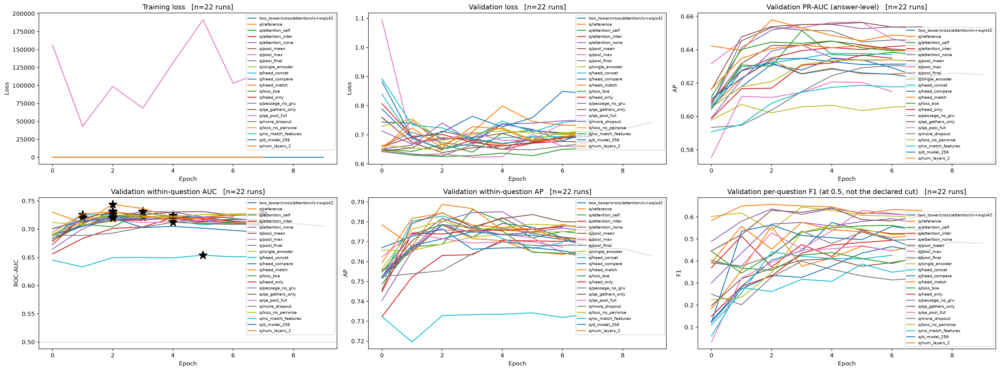


Held-out test metrics, using each run's best-validation checkpoint
Experiment                      trunc     sel    thr   yes%     AUC      AP    qAUC     qAP   F1@.50   F1@cut     qEM     qF1
--------------------------------------------------------------------------------------------------------------------------------------------
two_tower/cross/attention/ix+wq/s42  head_tail  0.7245  0.020  42.9%  0.6612  0.6136  0.6808  0.7430   0.5834   0.5742  0.1532  0.5373
q/reference                 head_tail  0.7266  0.016  43.2%  0.6589  0.6093  0.6899  0.7471   0.5852   0.5871  0.1658  0.5552
q/attention_self            head_tail  0.7305  0.012  42.8%  0.6771  0.6302  0.6906  0.7488   0.5675   0.5906  0.1658  0.5590
q/attention_inter           head_tail  0.7204  0.005  44.4%  0.6617  0.6166  0.6716  0.7354   0.4941   0.5772  0.1542  0.5559
q/attention_none            head_tail  0.7315  0.016  43.3%  0.6807  0.6411  0.6834  0.7455   0.6018   0.5825  0.1469  0.5465
q/pool_mean               

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(24, 9))
panels = [
    (axes[0][0], "train_loss", "Training loss", "Loss", False),
    (axes[0][1], "val_loss", "Validation loss", "Loss", False),
    (axes[0][2], "val_ap", "Validation PR-AUC (answer-level)", "AP", False),
    (axes[1][0], "val_q_auc", "Validation within-question AUC", "ROC-AUC", True),
    (axes[1][1], "val_q_ap", "Validation within-question AP", "AP", False),
    (axes[1][2], "val_q_f1", "Validation per-question F1 (at 0.5, uncalibrated)", "F1", False),
]

for ax, key, title, ylabel, is_auc in panels:
    plotted = 0
    for label, hist in experiments.items():
        if key not in hist:
            continue
        ax.plot(hist[key], label=label)
        if key == EARLY_STOP_METRIC:
            best_idx = hist["best_epoch"] - 1
            ax.plot(
                [best_idx],
                [hist[key][best_idx]],
                marker="*",
                markersize=16,
                color="black",
            )
        plotted += 1

    ax.set_title(f"{title}   [n={plotted} runs]")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    if is_auc:
        ax.axhline(0.5, color="grey", linestyle=":", linewidth=1)
    if plotted:
        ax.legend(fontsize=7)
    else:
        ax.text(
            0.5,
            0.5,
            "not recorded\n(this run predates the metric)",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=11,
        )

plt.tight_layout()
plt.show()

print("\n" + "=" * 140)
print("Held-out test metrics, using each run's best-validation checkpoint")
print("=" * 140)
print(
    f"{'Experiment':<26}{'trunc':>11}{'sel':>8}{'thr':>7}{'yes%':>7}{'AUC':>8}"
    f"{'AP':>8}{'qAUC':>8}{'qAP':>8}{'F1@.50':>9}{'F1@cut':>9}{'qEM':>8}{'qF1':>8}"
)
print("-" * 140)

reference_metrics = None
for label, hist in experiments.items():
    thr = hist.get("threshold", 0.5)
    model_obj = models[label]
    loader_obj = test_loaders.get(label, test_loader)
    rule_name = hist.get("threshold_rule") or THRESHOLD_RULE

    eval_res = evaluate(model_obj, loader_obj, threshold=thr, rule=rule_name)
    if reference_metrics is None:
        reference_metrics = eval_res

    f1_half = f1_score(
        eval_res["labels"],
        [int(s > 0.5) for s in eval_res["scores"]],
        zero_division=0,
    )
    sel_metric = hist.get(f"best_{EARLY_STOP_METRIC}") or hist["best_score"]
    trunc_mode = str(hist.get("truncation") or PASSAGE_TRUNCATION)

    print(
        f"{label:<26}{trunc_mode:>11}"
        f"{sel_metric:>8.4f}"
        f"{thr:>7.3f}"
        f"{eval_res['yes_rate'] * 100:>6.1f}%"
        f"{eval_res['auc']:>8.4f}{eval_res['ap']:>8.4f}"
        f"{eval_res['q_auc']:>8.4f}{eval_res['q_ap']:>8.4f}"
        f"{f1_half:>9.4f}"
        f"{eval_res['f1']:>9.4f}{eval_res['q_em']:>8.4f}{eval_res['q_f1']:>8.4f}"
    )

print("=" * 140)
print("Reference points on the same test split (no model):")
for name, pred_val in (("always-yes", 1), ("always-no", 0)):
    preds = [pred_val] * len(reference_metrics["labels"])
    q_metrics = per_question_metrics(
        reference_metrics["qids"], reference_metrics["labels"], preds
    )
    print(
        f"  {name:<11} "
        f"F1={f1_score(reference_metrics['labels'], preds, zero_division=0):.4f}"
        f"    qEM={q_metrics['q_em']:.4f}    qF1={q_metrics['q_f1']:.4f}"
        f"    accuracy={accuracy_score(reference_metrics['labels'], preds):.4f}"
    )
print(
    f"  (split baseline: {sum(reference_metrics['labels']) / len(reference_metrics['labels']):.1%} "
    f"positive, {reference_metrics['n_questions']} questions)"
)
print("=" * 126)

### Qualitative analysis: where the attention actually goes

The report asks for attention to be examined on examples the model gets right *and*
examples it gets wrong, with the inputs and the expected answers shown so the figures can
be interpreted. That is what the cell below does, for the best run in `experiments`:

- the passage is split back into the sentences MultiRC supplies, and the sentences the
  dataset marks as **supporting** the question (`sentences_used`) are highlighted, so the
  attention can be read against the evidence rather than against an impression;
- **answer-to-passage attention** is shown token by token and summed per sentence: with
  `attention="cross"` that is the cross-attention weight, and with `attention="inter"` it
  is the bilinear token-match distribution of the ESIM alignment -- in both cases it is
  where the model looked when it was judging the answer in front of it;
- **pooling weights** are shown beside it, because what reaches the classifier is the
  pooled vector, not the attention: a model can look somewhere and then not use it.

`SelfAttention`/`CrossAttention`/`AttentionPooling` each carry a `capture_attention` flag,
off during training, switched on only for the forward passes in this cell. Nothing about
the model or its numbers changes.

Two things to look for, both of which the previous run could not show: whether the mass
lands on the supporting sentence at all, and whether it lands there *more* on the question
the model got right than on the one it got wrong. A model that scores 0.5 within a question
has, by construction, an attention distribution that does not separate the correct answer
from the incorrect ones sharing its passage -- and MultiRC's candidate answers for one
question share the passage, so the figure is directly about that comparison.

## Dataset Statistics

Overview of the MultiRC dataset distribution, vocabulary, and structure.

In [ ]:
from collections import Counter
import numpy as np
import torch

passage_word_counts = []
question_word_counts = []
answer_word_counts = []
tokens_per_example = []
all_tokens = []

for passage, question, answer, _ in flat_train:
    p_tokens = tokenize(passage)
    q_tokens = tokenize(question)
    a_tokens = tokenize(answer)

    passage_word_counts.append(len(p_tokens))
    question_word_counts.append(len(q_tokens))
    answer_word_counts.append(len(a_tokens))
    tokens_per_example.append(len(p_tokens) + len(q_tokens) + len(a_tokens))

    all_tokens.extend(p_tokens)
    all_tokens.extend(q_tokens)
    all_tokens.extend(a_tokens)

word_freq = Counter(all_tokens)
word_freq_values = sorted(word_freq.values(), reverse=True)

train_labels_list = [lbl for _, _, _, lbl in flat_train]
test_labels_list = [lbl for _, _, _, lbl in flat_test]
train_pos_count = sum(train_labels_list)
test_pos_count = sum(test_labels_list)

questions_per_passage = []
answers_per_question = []
for item in train_data:
    paragraph = item["paragraph"]
    questions_per_passage.append(len(paragraph["questions"]))
    for q in paragraph["questions"]:
        answers_per_question.append(len(q["answers"]))

test_word_set = set()
for passage, question, answer, _ in flat_test:
    for token in tokenize(passage) + tokenize(question) + tokenize(answer):
        test_word_set.add(token)

train_word_set = set(word_freq.keys())
test_only_words = len(test_word_set - train_word_set)

# Unknown token analysis per split and field
_unk_passages = {}
for idx, example in enumerate(flat_train):
    _unk_passages.setdefault(example[0], []).append(idx)

_unk_keys = sorted(_unk_passages)
_generator = torch.Generator().manual_seed(SEED)
_unk_order = torch.randperm(len(_unk_keys), generator=_generator).tolist()
_unk_keys = [_unk_keys[j] for j in _unk_order]

_val_count = int(VAL_FRACTION * len(_unk_keys))
_unk_val_keys = set(_unk_keys[:_val_count])
_unk_val_rows = []
for k in _unk_keys:
    if k in _unk_val_keys:
        for idx in _unk_passages[k]:
            _unk_val_rows.append(flat_train[idx])

unk_rates = {}
for split_name, rows in (("val", _unk_val_rows), ("test", flat_test)):
    counts = {field: [0, 0] for field in ("passage", "question", "answer")}
    for passage, question, answer, _ in rows:
        for field, text in (("passage", passage), ("question", question), ("answer", answer)):
            for token in tokenize(text):
                counts[field][1] += 1
                if token not in vocab:
                    counts[field][0] += 1
    unk_rates[split_name] = counts

Validation: the selection metric, next to the decoders that turn a ranking into a decision
run                                AP    AUC    qAUC    qAP  qF1[global] qF1[within] qF1[oracle]qF1[alwaysY]  qEM[within]   no%  yes%
--------------------------------------------------------------------------------------------------------------------------------------
two_tower/cross/attention/ix+wq/s42 0.6346 0.6804  0.7245 0.7792       0.4855      0.5907      0.5954      0.6015       0.1593   18%   11%
--------------------------------------------------------------------------------------------------------------------------------------
qAUC/qAP     mean within-question AUC / AP over questions with both labels.
qF1[oracle]  q_f1 with a perfect per-question count (a CEILING, not a method);
             qF1[alwaysY] is the trivial reference.
no%/yes%     share of questions one global cut pushes to no-for-all / yes-for-all.



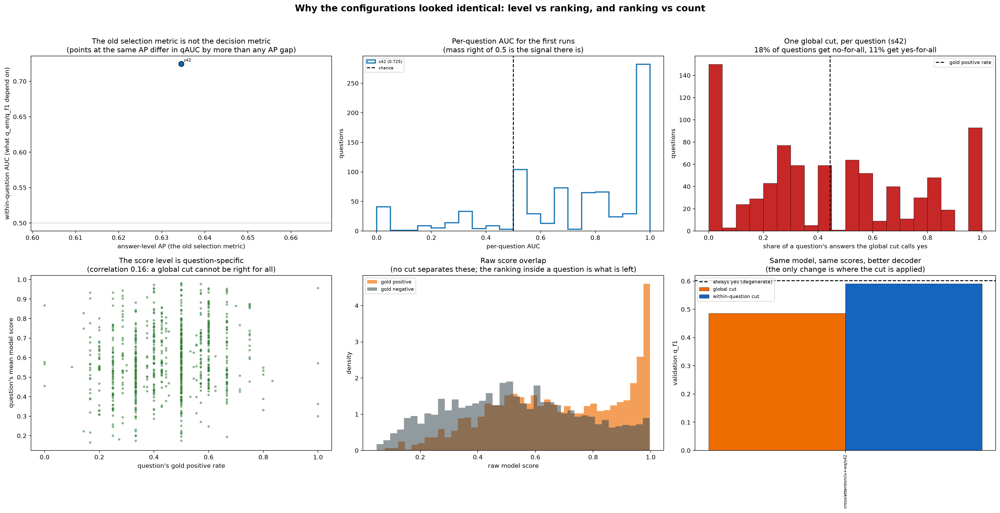

Paired comparison needs at least two configurations with the same seed and the within-question metric recorded (run the grid or the quick screen first).


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score


def _group_qids(qids):
    groups = {}
    for idx, q in enumerate(qids):
        groups.setdefault(q, []).append(idx)
    return groups


def _within_question(labels, scores, qids):
    aucs = []
    aps = []
    for rows in _group_qids(qids).values():
        gold_vec = [labels[i] for i in rows]
        if len(set(gold_vec)) < 2:
            continue
        score_vec = [scores[i] for i in rows]
        aucs.append(roc_auc_score(gold_vec, score_vec))
        aps.append(average_precision_score(gold_vec, score_vec))
    return aucs, aps


def _decoder_table(labels, scores, qids):
    out = {}
    for name, rule in (("global cut", "prior_match"), ("within-question cut", "within_question")):
        thr = declared_threshold(labels, scores, qids, rule=rule)
        preds = [int(s > thr) for s in decision_scores(scores, qids, rule)]
        m = per_question_metrics(qids, labels, preds)
        out[name] = (m["q_f1"], m["q_em"], sum(preds) / max(len(preds), 1))

    prior = float(sum(labels)) / max(len(labels), 1)
    oracle_preds = [0] * len(labels)
    for rows in _group_qids(qids).values():
        k = int(round(prior * len(rows)))
        for i in sorted(rows, key=lambda j: -scores[j])[:k]:
            oracle_preds[i] = 1

    oracle_metrics = per_question_metrics(qids, labels, oracle_preds)
    out["oracle count"] = (
        oracle_metrics["q_f1"],
        oracle_metrics["q_em"],
        sum(oracle_preds) / max(len(oracle_preds), 1),
    )

    always_yes_metrics = per_question_metrics(qids, labels, [1] * len(labels))
    out["always yes"] = (always_yes_metrics["q_f1"], always_yes_metrics["q_em"], 1.0)
    return out


def _cut_extremes(labels, scores, qids):
    thr = declared_threshold(labels, scores, qids, rule="prior_match")
    none_count = 0
    all_count = 0
    groups = _group_qids(qids)

    for rows in groups.values():
        pos_rate = sum(1 for i in rows if scores[i] > thr) / len(rows)
        none_count += int(pos_rate == 0.0)
        all_count += int(pos_rate == 1.0)

    n_groups = max(len(groups), 1)
    return none_count / n_groups, all_count / n_groups


runs_data = []
for label in sorted(experiments):
    if label not in models:
        continue
    if experiments[label].get("kind") == "screen":
        continue

    metrics = evaluate(models[label], val_loader, rule="prior_match")
    labels = metrics["labels"]
    scores = metrics["scores"]
    qids = metrics["qids"]

    aucs, aps = _within_question(labels, scores, qids)
    runs_data.append({
        "label": label,
        "ap": metrics["ap"],
        "auc": metrics["auc"],
        "q_auc": float(np.mean(aucs)) if aucs else float("nan"),
        "q_ap": float(np.mean(aps)) if aps else float("nan"),
        "per_q_auc": aucs,
        "decoders": _decoder_table(labels, scores, qids),
        "extremes": _cut_extremes(labels, scores, qids),
        "labels": labels,
        "scores": scores,
        "qids": qids,
    })

if not runs_data:
    raise RuntimeError("No trained runs available in memory for diagnostics.")

print("=" * 134)
print("Validation: selection metric vs decoders")
print("=" * 134)
print(
    f"{'run':<30}{'AP':>7}{'AUC':>7}{'qAUC':>8}{'qAP':>7}  "
    f"{'qF1[global]':>11}{'qF1[within]':>12}{'qF1[oracle]':>12}{'qF1[alwaysY]':>12}  "
    f"{'qEM[within]':>11}{'no%':>6}{'yes%':>6}"
)
print("-" * 134)

for r in runs_data:
    dec = r["decoders"]
    print(
        f"{r['label']:<30}{r['ap']:>7.4f}{r['auc']:>7.4f}{r['q_auc']:>8.4f}"
        f"{r['q_ap']:>7.4f}  "
        f"{dec['global cut'][0]:>11.4f}{dec['within-question cut'][0]:>12.4f}"
        f"{dec['oracle count'][0]:>12.4f}{dec['always yes'][0]:>12.4f}  "
        f"{dec['within-question cut'][1]:>11.4f}"
        f"{r['extremes'][0] * 100:>5.0f}%{r['extremes'][1] * 100:>5.0f}%"
    )
print("-" * 134)

fig, axes = plt.subplots(2, 3, figsize=(23, 12))
fig.suptitle(
    "Diagnostics: level vs ranking, and ranking vs count",
    fontsize=15,
    fontweight="bold",
)

# 1. Selection metric vs within-question AUC
ax = axes[0][0]
ax_ap = [r["ap"] for r in runs_data]
ax_q = [r["q_auc"] for r in runs_data]
ax.scatter(ax_ap, ax_q, s=70, c="#1565C0", edgecolor="black", zorder=3)
for r in runs_data:
    ax.annotate(
        r["label"].split("/")[-1],
        (r["ap"], r["q_auc"]),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points",
    )
ax.axhline(0.5, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("Answer-level AP")
ax.set_ylabel("Within-question AUC")
ax.set_title("Selection AP vs within-question AUC")

# 2. Per-question AUC distribution
ax = axes[0][1]
for r, color in zip(runs_data[:6], plt.cm.tab10.colors):
    ax.hist(
        r["per_q_auc"],
        bins=np.linspace(0, 1, 21),
        histtype="step",
        linewidth=2,
        color=color,
        label=f"{r['label'].split('/')[-1]} ({r['q_auc']:.3f})",
    )
ax.axvline(0.5, color="black", linestyle="--", linewidth=1.5, label="chance")
ax.set_xlabel("Per-question AUC")
ax.set_ylabel("Questions")
ax.set_title("Per-question AUC distribution")
ax.legend(fontsize=7)

# 3. Global cut distribution per question
ax = axes[0][2]
first_run = runs_data[0]
first_thr = declared_threshold(
    first_run["labels"], first_run["scores"], first_run["qids"], rule="prior_match"
)
question_groups = _group_qids(first_run["qids"])
rates = [
    sum(1 for i in rows if first_run["scores"][i] > first_thr) / len(rows)
    for rows in question_groups.values()
]
ax.hist(rates, bins=np.linspace(0, 1, 21), color="#C62828", edgecolor="black", linewidth=0.4)
ax.axvline(
    sum(first_run["labels"]) / len(first_run["labels"]),
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="gold positive rate",
)
ax.set_xlabel("Share of question answers predicted yes")
ax.set_ylabel("Questions")
ax.set_title(
    f"Global cut distribution ({first_run['label'].split('/')[-1]})\n"
    f"{first_run['extremes'][0]:.0%} no-for-all, {first_run['extremes'][1]:.0%} yes-for-all"
)
ax.legend(fontsize=8)

# 4. Score level vs gold positive rate
ax = axes[1][0]
q_mean = [
    np.mean([first_run["scores"][i] for i in rows])
    for rows in question_groups.values()
]
q_rate = [
    np.mean([first_run["labels"][i] for i in rows])
    for rows in question_groups.values()
]
ax.scatter(q_rate, q_mean, s=16, alpha=0.55, c="#2E7D32", edgecolor="none")
ax.set_xlabel("Question gold positive rate")
ax.set_ylabel("Question mean model score")
corr = np.corrcoef(q_rate, q_mean)[0, 1]
ax.set_title(f"Score level vs gold positive rate (r={corr:.2f})")

# 5. Raw score density
ax = axes[1][1]
scores_pos = [
    first_run["scores"][i] for i in range(len(first_run["labels"])) if first_run["labels"][i] == 1
]
scores_neg = [
    first_run["scores"][i] for i in range(len(first_run["labels"])) if first_run["labels"][i] == 0
]
ax.hist(scores_pos, bins=40, alpha=0.65, color="#EF6C00", label="gold positive", density=True)
ax.hist(scores_neg, bins=40, alpha=0.55, color="#37474F", label="gold negative", density=True)
ax.set_xlabel("Model score")
ax.set_ylabel("Density")
ax.set_title("Raw score overlap")
ax.legend(fontsize=8)

# 6. Decoder effect across runs
ax = axes[1][2]
x_pos = np.arange(len(runs_data))
global_f1s = [r["decoders"]["global cut"][0] for r in runs_data]
within_f1s = [r["decoders"]["within-question cut"][0] for r in runs_data]
ax.bar(x_pos - 0.21, global_f1s, 0.42, label="global cut", color="#EF6C00", edgecolor="black", linewidth=0.4)
ax.bar(x_pos + 0.21, within_f1s, 0.42, label="within-question cut", color="#1565C0", edgecolor="black", linewidth=0.4)
ax.axhline(
    runs_data[0]["decoders"]["always yes"][0],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="always yes reference",
)
ax.set_xticks(x_pos)
ax.set_xticklabels(
    [r["label"].replace("two_tower/", "").replace("single/", "1t/") for r in runs_data],
    rotation=90,
    fontsize=7,
)
ax.set_ylabel("Validation q_f1")
ax.set_title("Decoder comparison: global vs within-question cut")
ax.legend(fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Paired seed comparison
paired = {}
for label, hist in experiments.items():
    cfg = hist.get("config")
    seed_val = hist.get("seed")
    if cfg and seed_val is not None and hist.get("best_val_q_auc") is not None:
        paired.setdefault(cfg, {})[seed_val] = hist["best_val_q_auc"]

if len(paired) > 1:
    best_cfg = max(paired, key=lambda c: np.mean(list(paired[c].values())))
    print(
        f"Paired by seed against {best_cfg} "
        f"(mean val q_auc {np.mean(list(paired[best_cfg].values())):.4f}):"
    )
    print(
        f"  {'configuration':<28}{'seeds':>6}{'val qAUC':>10}{'mean delta':>12}"
        f"{'worst':>9}{'best':>9}"
    )
    for cfg in sorted(paired, key=lambda c: -np.mean(list(paired[c].values()))):
        shared_seeds = sorted(set(paired[best_cfg]) & set(paired[cfg]))
        if not shared_seeds:
            continue
        deltas = [paired[cfg][s] - paired[best_cfg][s] for s in shared_seeds]
        mark = ""
        if cfg != best_cfg:
            mark = "   <- consistent" if (min(deltas) > 0 or max(deltas) < 0) else "   <- flips sign"
        print(
            f"  {cfg:<28}{len(shared_seeds):>6}"
            f"{np.mean(list(paired[cfg].values())):>10.4f}"
            f"{np.mean(deltas):>12.4f}{min(deltas):>9.4f}{max(deltas):>9.4f}{mark}"
        )

Attention figures -- q/head_match (cut 0.013 on within_question scores, decision by val_q_auc)
Scanned 120 test questions for an example of each kind: ['correct', 'incorrect']
Attention on the dataset's supporting sentence(s): 120 question(s), 586 candidate(s), chance 0.165, decided-correct 0.155, decided-wrong 0.164



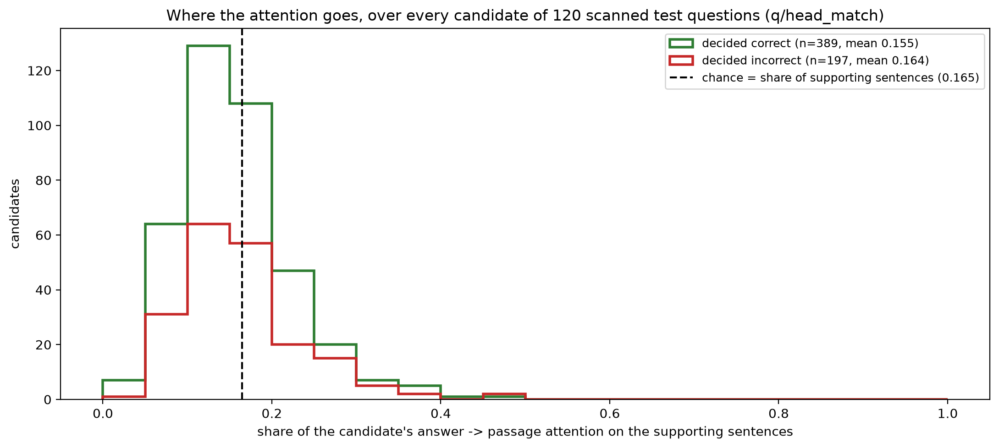

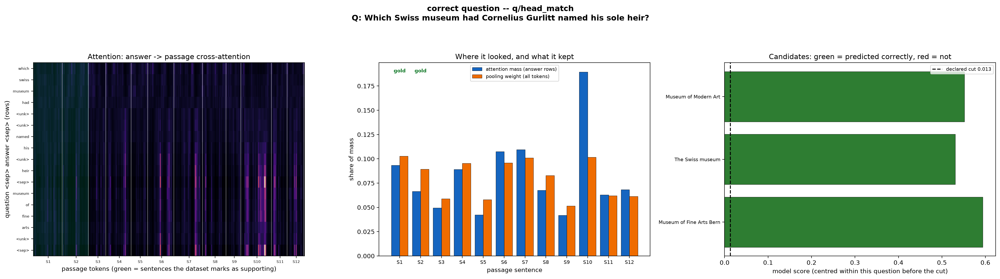

--- correct question: Which Swiss museum had Cornelius Gurlitt named his sole heir?
    answers: yes/yes 0.594 Museum of Fine Arts Bern | no /no  0.531 The Swiss museum | no /no  0.552 Museum of Modern Art
    S1  attn 0.093  pool 0.103 <- gold  (CNN) -- German art collector Cornelius Gurlitt, whose nearly priceless collection was confiscat...
    S2  attn 0.067  pool 0.089 <- gold  One day after Gurlitt's death at the age of 81, the Museum of Fine Arts Bern announced that Gurl...
    S3  attn 0.049  pool 0.059  The news came as a surprise, the museum said Wednesday, because Gurlitt had never had any connec...
    S4  attn 0.089  pool 0.095  The museum's directors are delighted at the news, they said in a statement, but also recognize t...
    S5  attn 0.042  pool 0.058  Gurlitt had undergone major heart surgery and was hospitalized for many weeks, his representativ...
    S6  attn 0.108  pool 0.096  Gurlitt grabbed the attention of the art world when German prosecutors seized more tha

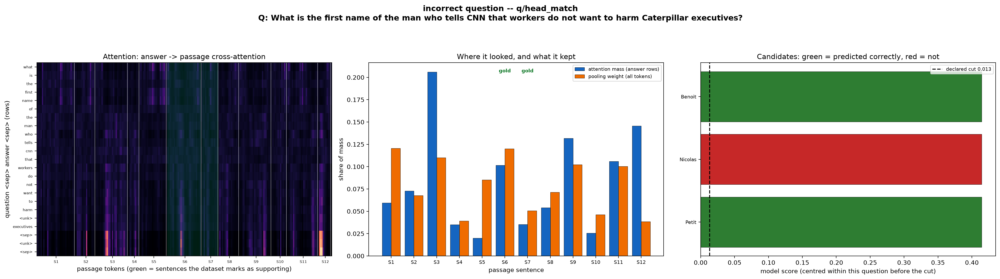

--- incorrect question: What is the first name of the man who tells CNN that workers do not want to harm Caterpillar executives?
    answers: no /no  0.414 Petit | no /yes 0.414 Nicolas | no /no  0.414 Benoit
    S1  attn 0.059  pool 0.121  Paris, France (CNN) -- Hundreds of French workers, angry about proposed layoffs at a Caterpillar...
    S2  attn 0.073  pool 0.068  Caterpillar's French staff say they are angry about a lack of negotiations over layoffs.
    S3  attn 0.206  pool 0.110  It is at least the third time this month that French workers threatened with cutbacks have block...
    S4  attn 0.035  pool 0.039  Executives were released unharmed in both previous situations.
    S5  attn 0.020  pool 0.085  The latest incident started Tuesday morning at the office of the construction equipment company ...
    S6  attn 0.101  pool 0.120 <- gold  The workers were angry that Caterpillar had proposed cutting more than 700 jobs and would not ne...
    S7  attn 0.035  pool 0.051 <- gold 

In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch


def _rank_key(hist):
    return hist.get(f"best_{EARLY_STOP_METRIC}") or hist.get("best_val_ap") or 0.0


ranked_models = [k for k in experiments if k in models]
run_name = max(ranked_models, key=lambda k: _rank_key(experiments[k]))
model = models[run_name]
rule = experiments[run_name].get("threshold_rule") or THRESHOLD_RULE
cut = experiments[run_name].get("threshold", 0.5)
id_to_token = {i: t for t, i in vocab.items()}


def _answer_rows(ids):
    seps = [i for i, t in enumerate(ids) if t == SEP_ID]
    if len(seps) >= 2:
        rows = list(range(seps[0] + 1, seps[1]))
        if rows:
            return rows
    return [i for i, t in enumerate(ids) if t != PAD_ID]


def _sentence_spans(ids):
    spans = []
    start = 0
    for i, t in enumerate(ids):
        if t == SEP_ID:
            spans.append((start, i))
            start = i + 1
    if start < len(ids):
        spans.append((start, len(ids)))
    return [(s, e) for s, e in spans if e > s]


def _untruncated_length(text):
    return sum(len(tokenize(sentence)) + 1 for sentence in text.split(SENT_SEP))


def _capture_attention_weights(enabled):
    for m in model.modules():
        if hasattr(m, "capture_attention"):
            m.capture_attention = enabled


def _forward_with_attention(passage, question, answers, keep_attention):
    passage_batch = [encode_passage(passage) for _ in answers]
    qa_batch = [encode_qa(question, a) for a, _ in answers]
    pids = pad_sequences(passage_batch).to(DEVICE)
    qids = pad_sequences(qa_batch).to(DEVICE)

    model.eval()
    _capture_attention_weights(keep_attention)
    try:
        with torch.no_grad():
            logits = model(pids, qids)
    finally:
        _capture_attention_weights(False)

    scores = torch.sigmoid(logits).cpu().tolist()
    preds = [int(s > cut) for s in decision_scores(scores, [0] * len(scores), rule)]

    out = {
        "passage_ids": pids[0].cpu().tolist(),
        "qa_ids": [qids[b].cpu().tolist() for b in range(qids.size(0))],
        "scores": scores,
        "preds": preds,
    }

    for name, attr in (
        ("cross", "qa_to_passage"),
        ("inter", "inter"),
        ("pool", "passage_pool"),
        ("self", "passage_self_attn"),
    ):
        module_obj = getattr(model, attr, None)
        weights = getattr(module_obj, "last_weights", None) if module_obj else None
        out[name] = weights.float().cpu().numpy() if weights is not None else None

    return out


grouped_test = {}
for passage, question, answer, label in flat_test:
    grouped_test.setdefault((passage, question), []).append((answer, bool(label)))

gold_evidence = {}
for item in test_data:
    clean_p = clean_passage(item["paragraph"]["text"])
    for q in item["paragraph"]["questions"]:
        gold_evidence[(clean_p, q["question"])] = [
            int(s) for s in (q.get("sentences_used") or [])
        ]

scan_keys = random.Random(SAMPLE_SEED).sample(
    sorted(grouped_test), min(N_ATTENTION_SCAN, len(grouped_test))
)
picked_examples = {}
support_mass = {"correct": [], "incorrect": []}
support_chance = []

for key in scan_keys:
    passage, question = key
    if _untruncated_length(passage) > PASSAGE_MAX_TOKENS:
        continue

    answers = grouped_test[key]
    res = _forward_with_attention(passage, question, answers, True)
    slot = (
        "correct"
        if all(p == g for p, (_, g) in zip(res["preds"], answers))
        else "incorrect"
    )
    picked_examples.setdefault(slot, key)

    gold_here = set(gold_evidence.get(key, []))
    spans_here = _sentence_spans(res["passage_ids"])
    map_here = res["cross"] if res["cross"] is not None else res["inter"]

    if gold_here and map_here is not None and len(spans_here) == len(passage.split(SENT_SEP)):
        support_chance.append(len(gold_here) / len(spans_here))
        for b, (_, gold_flag) in enumerate(answers):
            weights = map_here[b].mean(axis=0)
            answer_indices = _answer_rows(res["qa_ids"][b])
            mass = weights[answer_indices].sum(axis=0)
            mass = mass / max(mass.sum(), 1e-9)

            target_slot = "correct" if res["preds"][b] == gold_flag else "incorrect"
            assigned_mass = float(
                sum(
                    mass[spans_here[g][0] : spans_here[g][1]].sum()
                    for g in gold_here
                    if g < len(spans_here)
                )
            )
            support_mass[target_slot].append(assigned_mass)

print(
    f"Attention figures -- {run_name} "
    f"(cut {cut:.3f} on {rule} scores, decision by {EARLY_STOP_METRIC})"
)
print(f"Scanned {len(scan_keys)} test questions: {sorted(picked_examples)}")

if support_chance:
    correct_mean = np.mean(support_mass["correct"]) if support_mass["correct"] else float("nan")
    incorrect_mean = np.mean(support_mass["incorrect"]) if support_mass["incorrect"] else float("nan")
    total_candidates = len(support_mass["correct"]) + len(support_mass["incorrect"])
    print(
        f"Attention on supporting sentences: {len(support_chance)} questions, "
        f"{total_candidates} candidates, chance {np.mean(support_chance):.3f}, "
        f"decided-correct {correct_mean:.3f}, decided-wrong {incorrect_mean:.3f}\n"
    )
else:
    print("No scanned candidate met the criteria for aggregate attention analysis.\n")

if support_chance and (support_mass["correct"] or support_mass["incorrect"]):
    fig, ax = plt.subplots(figsize=(11, 5))
    bins = np.linspace(0, 1, 21)
    for slot, colour in (("correct", "#2E7D32"), ("incorrect", "#C62828")):
        vals = support_mass[slot]
        if vals:
            ax.hist(
                vals,
                bins=bins,
                histtype="step",
                linewidth=2,
                color=colour,
                label=f"decided {slot} (n={len(vals)}, mean {np.mean(vals):.3f})",
            )
    mean_chance = float(np.mean(support_chance))
    ax.axvline(
        mean_chance,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"chance = supporting sentence ratio ({mean_chance:.3f})",
    )
    ax.set_xlabel("Attention mass on supporting sentences")
    ax.set_ylabel("Candidates")
    ax.set_title(f"Attention on supporting sentences ({len(scan_keys)} questions, {run_name})")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

for slot in ("correct", "incorrect"):
    if slot not in picked_examples:
        print(f"No {slot} example found among scanned questions.")
        continue

    passage, question = picked_examples[slot]
    answers = grouped_test[(passage, question)]
    res = _forward_with_attention(passage, question, answers, True)
    sentences = passage.split(SENT_SEP)
    spans = _sentence_spans(res["passage_ids"])
    gold_idx = set(gold_evidence.get((passage, question), []))

    token_mass = None
    source = "attention='none'"
    if res["cross"] is not None:
        w = res["cross"][0].mean(axis=0)
        token_mass = w[_answer_rows(res["qa_ids"][0])].sum(axis=0)
        source = "answer -> passage cross-attention"
    elif res["self"] is not None:
        token_mass = res["self"][0].mean(axis=0).sum(axis=0)
        source = "passage self-attention"
    elif res["inter"] is not None:
        w = res["inter"][0].mean(axis=0)
        token_mass = w[_answer_rows(res["qa_ids"][0])].sum(axis=0)
        source = "inter-attention token match"

    if token_mass is not None:
        token_mass = token_mass / max(token_mass.sum(), 1e-9)
        sent_mass = [token_mass[s:e].sum() for s, e in spans]
    else:
        sent_mass = None

    pool_mass = None
    if res["pool"] is not None:
        pool_mass = [res["pool"][0][s:e].sum() for s, e in spans]

    fig, axes = plt.subplots(1, 3, figsize=(23, 6.5))
    fig.suptitle(
        f"{slot.capitalize()} question -- {run_name}\nQ: {question}",
        fontsize=13,
        fontweight="bold",
    )

    # 1. Token-level map
    ax = axes[0]
    if token_mass is not None and (res["cross"] is not None or res["inter"] is not None):
        attn_map = (res["cross"] if res["cross"] is not None else res["inter"])[0].mean(axis=0)
        ax.imshow(attn_map, aspect="auto", cmap="magma", origin="upper")
        ax.set_yticks(range(len(res["qa_ids"][0])))
        ax.set_yticklabels([id_to_token.get(int(t), "pad") for t in res["qa_ids"][0]], fontsize=6)
        ax.set_ylabel("question <sep> answer <sep>")
    else:
        ax.imshow(np.zeros((2, len(res["passage_ids"]))), aspect="auto", cmap="magma")
        ax.text(0.5, 0.5, "no cross-attention", ha="center", va="center", transform=ax.transAxes, fontsize=11)

    for s, e in spans:
        ax.axvline(e - 0.5, color="white", linewidth=0.6, alpha=0.7)
    for g in sorted(gold_idx):
        if g < len(spans):
            ax.axvspan(spans[g][0] - 0.5, spans[g][1] - 0.5, color="#00E676", alpha=0.13, zorder=0)

    ax.set_xticks([(s + e) / 2 for s, e in spans])
    ax.set_xticklabels([f"S{i + 1}" for i in range(len(spans))], fontsize=6)
    ax.set_xlabel("Passage tokens (green = supporting sentences)")
    ax.set_title(f"Attention: {source}")

    # 2. Sentence-level attention mass vs pooling weight
    ax = axes[1]
    x_positions = np.arange(len(spans))
    if sent_mass is not None:
        ax.bar(
            x_positions - 0.2,
            sent_mass,
            0.4,
            label="attention mass (answer rows)",
            color="#1565C0",
            edgecolor="black",
            linewidth=0.4,
        )
    if pool_mass is not None:
        ax.bar(
            x_positions + 0.2,
            pool_mass,
            0.4,
            label="pooling weight (all tokens)",
            color="#EF6C00",
            edgecolor="black",
            linewidth=0.4,
        )

    for g in sorted(gold_idx):
        if g < len(spans):
            ax.text(g, ax.get_ylim()[1] * 0.95, "gold", ha="center", fontsize=8, color="#00701a", fontweight="bold")

    ax.set_xticks(x_positions)
    ax.set_xticklabels([f"S{i + 1}" for i in range(len(spans))], fontsize=8)
    ax.set_xlabel("Passage sentence")
    ax.set_ylabel("Share of mass")
    ax.set_title("Sentence-level attention and pooling")
    ax.legend(fontsize=8)

    # 3. Model candidate scores
    ax = axes[2]
    scores = res["scores"]
    bar_colors = ["#2E7D32" if p == g else "#C62828" for p, (_, g) in zip(res["preds"], answers)]
    ax.barh(range(len(answers)), scores, color=bar_colors, edgecolor="black", linewidth=0.4)
    ax.axvline(cut, color="black", linestyle="--", linewidth=1.5, label=f"declared cut {cut:.3f}")
    ax.set_yticks(range(len(answers)))
    ax.set_yticklabels(
        [(a[:44] + "...") if len(a) > 47 else a for a, _ in answers], fontsize=8
    )
    ax.set_xlabel("Model score")
    ax.set_title("Candidate predictions (green=correct, red=incorrect)")
    ax.legend(fontsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

    print(f"--- {slot.capitalize()} question: {question}")
    print(
        "    answers: "
        + " | ".join(
            f"{'yes' if p else 'no '}/{'yes' if g else 'no '} {s:.3f} "
            f"{(a[:40] + '..') if len(a) > 42 else a}"
            for s, p, (a, g) in zip(scores, res["preds"], answers)
        )
    )
    for i, (s, e) in enumerate(spans):
        mark = " <- gold" if i in gold_idx else ""
        att_str = f"attn {sent_mass[i]:.3f}" if sent_mass is not None else "attn n/a"
        pool_str = f"pool {pool_mass[i]:.3f}" if pool_mass is not None else "pool n/a"
        text_str = sentences[i] if i < len(sentences) else ""
        print(f"    S{i + 1:<3}{att_str}  {pool_str}{mark}  {text_str[:96]}")

    if sent_mass is not None:
        att_gold = sum(sent_mass[i] for i in gold_idx if i < len(sent_mass))
        print(
            f"    -> attention mass on supporting sentences: {att_gold:.1%} "
            f"(chance: {len(gold_idx) / max(len(spans), 1):.1%})\n"
        )

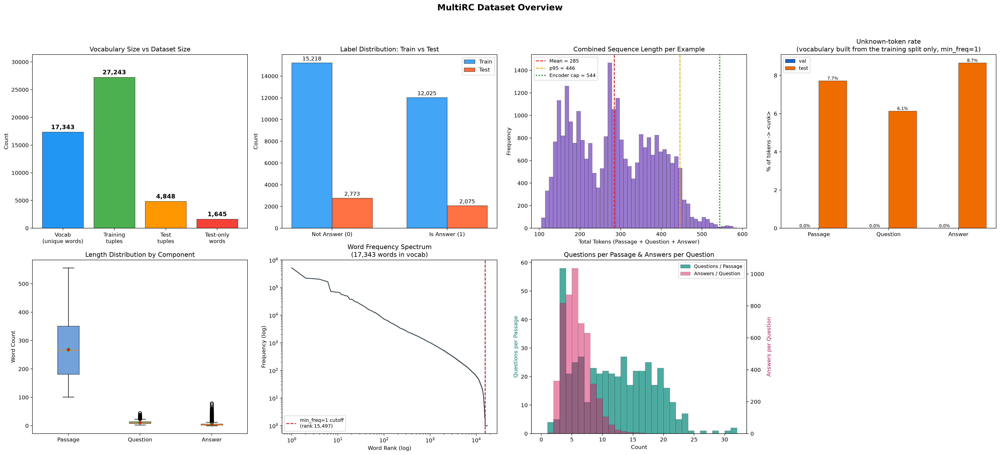

MultiRC Dataset Summary
Vocabulary size (min_freq=1):  17,343 unique words
Training tuples:               27,243
Test tuples:                   4,848
Train:Test ratio:              1:0.18
Train positive ratio:          44.1%
Test positive ratio:           42.8%
Passages in train:             456
Passages in test:               83
Avg questions per passage:     11.3
Avg answers per question:      5.3
Avg passage words:             268 (p95=428)
Avg question words:            11 (p95=21)
Avg answer words:              5 (p95=15)
Avg total tokens per example:  285 (p95=446)
Words appearing only in test:  1,645
Unknown tokens (val):         passage=0.00%  question=0.00%  answer=0.00%
Unknown tokens (test):        passage=7.72%  question=6.14%  answer=8.66%


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(26, 12))
fig.suptitle("MultiRC Dataset Overview", fontsize=16, fontweight="bold", y=0.98)

# 1. Vocabulary size vs dataset size
ax1 = axes[0, 0]
categories = ["Vocab\n(unique words)", "Training\ntuples", "Test\ntuples", "Test-only\nwords"]
values = [vocab_size, len(flat_train), len(flat_test), test_only_words]
colors = ["#2196F3", "#4CAF50", "#FF9800", "#F44336"]
bars = ax1.bar(categories, values, color=colors, edgecolor="black", linewidth=0.5)

for bar, val in zip(bars, values):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(values) * 0.01,
        f"{val:,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )
ax1.set_ylabel("Count")
ax1.set_title("Vocabulary Size vs Dataset Size")
ax1.set_ylim(0, max(values) * 1.15)

# 2. Label distribution
ax2 = axes[0, 1]
x_idx = np.arange(2)
width = 0.35
train_counts = [len(flat_train) - train_pos_count, train_pos_count]
test_counts = [len(flat_test) - test_pos_count, test_pos_count]

ax2.bar(x_idx - width / 2, train_counts, width, label="Train", color="#42A5F5", edgecolor="black", linewidth=0.5)
ax2.bar(x_idx + width / 2, test_counts, width, label="Test", color="#FF7043", edgecolor="black", linewidth=0.5)
for i, (tc, vc) in enumerate(zip(train_counts, test_counts)):
    ax2.text(x_idx[i] - width / 2, tc + 100, f"{tc:,}", ha="center", va="bottom", fontsize=10)
    ax2.text(x_idx[i] + width / 2, vc + 100, f"{vc:,}", ha="center", va="bottom", fontsize=10)
ax2.set_xticks(x_idx)
ax2.set_xticklabels(["Not Answer (0)", "Is Answer (1)"])
ax2.set_ylabel("Count")
ax2.set_title("Label Distribution: Train vs Test")
ax2.legend()

# 3. Combined sequence length per example
ax3 = axes[0, 2]
ax3.hist(tokens_per_example, bins=50, color="#7E57C2", edgecolor="black", linewidth=0.3, alpha=0.8)
ax3.axvline(
    np.mean(tokens_per_example),
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {np.mean(tokens_per_example):.0f}",
)
ax3.axvline(
    np.percentile(tokens_per_example, 95),
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label=f"p95 = {np.percentile(tokens_per_example, 95):.0f}",
)
ax3.axvline(
    PASSAGE_MAX_TOKENS + QA_MAX_TOKENS,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Encoder cap = {PASSAGE_MAX_TOKENS + QA_MAX_TOKENS}",
)
ax3.set_xlabel("Total Tokens (Passage + Question + Answer)")
ax3.set_ylabel("Frequency")
ax3.set_title("Combined Sequence Length per Example")
ax3.legend(fontsize=9)

# 4. Component length box plots
ax4 = axes[1, 0]
box_data = [passage_word_counts, question_word_counts, answer_word_counts]
bp = ax4.boxplot(
    box_data,
    tick_labels=["Passage", "Question", "Answer"],
    patch_artist=True,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "red", "markersize": 5},
)
box_colors = ["#1565C0", "#2E7D32", "#E65100"]
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax4.set_ylabel("Word Count")
ax4.set_title("Length Distribution by Component")

# 5. Word frequency spectrum (Zipfian)
ax5 = axes[1, 1]
ax5.loglog(range(1, len(word_freq_values) + 1), word_freq_values, color="#37474F", linewidth=1.5)
ax5.set_xlabel("Word Rank (log)")
ax5.set_ylabel("Frequency (log)")
ax5.set_title(f"Word Frequency Spectrum\n({vocab_size:,} words in vocab)")
cutoff_rank = sum(1 for f in word_freq_values if f >= 2)
ax5.axvline(
    cutoff_rank,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"min_freq={MIN_FREQ} cutoff\n(rank {cutoff_rank:,})",
)
ax5.legend(fontsize=9)

# 6. Questions per passage & answers per question
ax6 = axes[1, 2]
ax6.hist(
    questions_per_passage,
    bins=range(0, max(questions_per_passage) + 2),
    color="#00897B",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.7,
    label="Questions / Passage",
)
ax6b = ax6.twinx()
ax6b.hist(
    answers_per_question,
    bins=range(0, max(answers_per_question) + 2),
    color="#D81B60",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.5,
    label="Answers / Question",
)
ax6.set_xlabel("Count")
ax6.set_ylabel("Questions per Passage", color="#00897B")
ax6b.set_ylabel("Answers per Question", color="#D81B60")
ax6.set_title("Questions per Passage & Answers per Question")
h1, l1 = ax6.get_legend_handles_labels()
h2, l2 = ax6b.get_legend_handles_labels()
ax6.legend(h1 + h2, l1 + l2, fontsize=9, loc="upper right")

# 7. Unknown-token rate
ax7 = axes[0, 3]
fields = ["passage", "question", "answer"]
x_coords = np.arange(len(fields))
for split_name, offset, colour in (("val", -0.2, "#1565C0"), ("test", 0.2, "#EF6C00")):
    rates = [
        unk_rates[split_name][f][0] / max(unk_rates[split_name][f][1], 1) * 100
        for f in fields
    ]
    bar_group = ax7.bar(
        x_coords + offset,
        rates,
        0.4,
        color=colour,
        edgecolor="black",
        linewidth=0.4,
        label=split_name,
    )
    for bar, rate in zip(bar_group, rates):
        ax7.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{rate:.1f}%",
            ha="center",
            va="bottom",
            fontsize=8,
        )
ax7.set_xticks(x_coords)
ax7.set_xticklabels([f.capitalize() for f in fields])
ax7.set_ylabel("% of tokens -> <unk>")
ax7.set_title(f"Unknown-token rate (min_freq={MIN_FREQ})")
ax7.legend(fontsize=9)
axes[1, 3].axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("=" * 60)
print("MultiRC Dataset Summary")
print("=" * 60)
print(f"Vocabulary size (min_freq={MIN_FREQ}):  {vocab_size:,} unique words")
print(f"Training tuples:               {len(flat_train):,}")
print(f"Test tuples:                   {len(flat_test):,}")
print(f"Train:Test ratio:              1:{len(flat_test)/len(flat_train):.2f}")
print(f"Train positive ratio:          {train_pos_count/len(flat_train):.1%}")
print(f"Test positive ratio:           {test_pos_count/len(flat_test):.1%}")
print(f"Passages in train:             {len(train_data)}")
print(f"Passages in test:              {len(test_data)}")
print(f"Avg questions per passage:     {np.mean(questions_per_passage):.1f}")
print(f"Avg answers per question:      {np.mean(answers_per_question):.1f}")
print(f"Avg passage words:             {np.mean(passage_word_counts):.0f} (p95={np.percentile(passage_word_counts, 95):.0f})")
print(f"Avg question words:            {np.mean(question_word_counts):.0f} (p95={np.percentile(question_word_counts, 95):.0f})")
print(f"Avg answer words:              {np.mean(answer_word_counts):.0f} (p95={np.percentile(answer_word_counts, 95):.0f})")
print(f"Avg total tokens per example:  {np.mean(tokens_per_example):.0f} (p95={np.percentile(tokens_per_example, 95):.0f})")
print(f"Words appearing only in test:  {test_only_words:,}")
for split_name in ("val", "test"):
    rates_summary = "  ".join(
        f"{field}={unk_rates[split_name][field][0] / max(unk_rates[split_name][field][1], 1):.2%}"
        for field in ("passage", "question", "answer")
    )
    print(f"{'Unknown tokens (' + split_name + '):':<30}{rates_summary}")
print("=" * 60)

## 4. Ablation study

Two studies sharing one component list (the `ablation_components` cell), so they cannot
drift apart. They differ only in budget and in how many seeds they repeat:

- **`quick_ablation`** (`QUICK_ABLATION`) -- a one-change-at-a-time **screen** on a
  shortened budget (`QUICK_ABLATION_EPOCHS`) and a single seed, for ballpark triage: which
  variants look worth a full-budget run, and which are dead on arrival. Its runs are tagged
  `kind="screen"`, so the plots show them but **no reported table, no diagnostic and no
  model-vs-baselines row does**. It is a screen, not a result.
- **`final_ablation`** (`RUN_ABLATION_STUDY`) -- the **reported** study, at
  `ABLATION_EPOCHS` over `ABLATION_SEEDS`, covering every component.
- **the summary table** -- aggregates the reported runs and the baselines into one table.
- **the model-vs-baselines comparison** -- the same numbers as bars, with a
  passage-bootstrap interval and a paired test against each baseline.

All of them register their runs in `experiments`/`models`/`test_loaders`, so the plots,
the sample-answer cell, the attention figures and the summary table pick them up.

### The final study

This is the comparison the report is built on, so it is controlled:

- **One budget and one stopping rule.** Every configuration trains under the same
  schedule, with the same `EARLY_STOPPING` rule, and keeps its best-`EARLY_STOP_METRIC`
  epoch -- selected epoch by epoch, so the rule only removes epochs that could not have
  been selected and never changes which checkpoint is reported. The LR schedule is a pure
  function of the epoch index, so a run that stopped early still saw the same LR at the
  same epoch as one that ran on, and the comparison stays like-for-like.
- **Repeated over seeds, seeds outermost.** `ABLATION_SEEDS` runs each configuration
  several times, so the spread *between* configurations can be read against the spread
  *within* one. The seed loop is on the outside, so the study is already comparable after
  the first pass. The summary prints the means and the seed spread, and the diagnostics
  cell prints a paired-by-seed comparison: a difference that keeps its sign across every
  shared seed is separated by these runs, one that flips is noise.
- **Two blocks, covering every component.** The **architecture factorial** sweeps every
  `ENCODER_OPTIONS` x `ATTENTION_OPTIONS` x `POOLING_OPTIONS` architecture the encoder
  admits (with the shipped options, 6 encoder x attention combinations x 4 poolings = 24).
  Those three interact, so they are swept together as a cross product. The **component
  runs** then change exactly one thing at a time off the configured model, covering
  everything the factorial holds fixed: the head, the objective, the passage truncation,
  the passage encoder, the cross-attention direction, the question/answer pooling,
  dropout, the pairwise weight and the alignment features -- every entry of
  `COMPONENT_VARIANTS` in the `ablation_components` cell.
- **A reference that costs nothing.** The configured model
  (`ENCODER`/`ATTENTION`/`POOLING` in the hyperparameters cell) is itself a member of the
  architecture factorial, so every component run has a full-budget, same-seed reference
  already trained. The summary and the diagnostics compare them **paired seed by seed**,
  which cancels the seed effect and is the sensitive test. Set those three to the
  factorial's best configuration once the study has run.
- **The `"match"` guard.** The architecture axis is swept under the configured `HEAD`, and
  `HEAD` has to keep the pooled vectors in the classifier for the `POOLING` axis to be
  measurable: under `head="match"` the classifier reads *only* the alignment features, so
  every pooling setting would build the same function and the pooling axis would be
  several copies of one run. The shipped configuration is therefore `HEAD = "interaction"`,
  and the study refuses the `"match"` combination by name rather than printing a table of
  identical rows. `head="match"` is still ablated -- as a *component*, where it is the
  extreme that closes the answer-prior route by construction.

### Reading a component

- **head** -- what the classifier is fed. `concat` gives it the two pooled vectors
  (`[u; v]`); `interaction` adds the comparison (`[u; v; |u-v|; u*v]`); `compare` drops the
  bare vectors and keeps only terms that contain the passage (`[|u-v|; u*v]`); and `match`
  hands it *only* the passage-conditioned alignment features, so nothing in its input is
  computable from the question and answer alone. They differ in how much of the
  answer <-> passage comparison reaches the classifier.
- **objective** -- `bce` against `within_question`, which centres each question's candidate
  logits on their own mean and adds a pairwise ranking term (`PAIRWISE_WEIGHT`). The level
  of a question is a property of a passage the model has not seen at test time, so an
  objective that can lower itself by fitting it is spending capacity on something that
  cannot transfer.
- **the knobs the factorial holds fixed** -- `head_only` (passage truncation),
  `passage_no_gru`, `qa_gathers_only` (cross-attention direction), `qa_pool_full`,
  `more_dropout`, `loss_no_pairwise` and `no_match_features`.

Every run in the study registers in `experiments`/`models`/`test_loaders`, so the plots,
the sample-answer cell, the attention figures and the summary table pick them up, and each
run is cached to `ABLATION_CACHE_DIR` as it finishes, so an interrupted study resumes.

`len(ENCODER_OPTIONS)`-derived architectures x `len(ABLATION_SEEDS)` runs plus
`len(COMPONENT_VARIANTS)` x `len(ABLATION_SEEDS)` component runs, each at most
`ABLATION_EPOCHS` epochs (early stopping usually ends them before the budget). Trim
`ABLATION_SEEDS`, `POOLING_OPTIONS`, `ATTENTION_OPTIONS` or `COMPONENT_VARIANTS` if the
budget is tight.

In [ ]:
REFERENCE_VARIANT = ("reference", {})

GRID_AXIS_VARIANTS = [
    ("attention_self", {"attention": "self"}),
    ("attention_inter", {"attention": "inter"}),
    ("attention_none", {"attention": "none"}),
    ("pool_mean", {"pooling": "mean"}),
    ("pool_max", {"pooling": "max"}),
    ("pool_final", {"pooling": "final"}),
    ("single_encoder", {"encoder": "single", "attention": "self"}),
]

COMPONENT_VARIANTS = (
    [("head_" + h, {"head": h}) for h in HEAD_OPTIONS if h != HEAD]
    + [("loss_" + l, {"loss": l}) for l in LOSS_OPTIONS if l != LOSS]
    + [
        ("head_only", {"truncation": "head"}),
        ("passage_no_gru", {"passage_encoder": "none"}),
        ("qa_gathers_only", {"cross_direction": "qa_to_passage"}),
        ("qa_pool_full", {"qa_pooling": "full"}),
        ("more_dropout", {"dropout": 0.4}),
        ("loss_no_pairwise", {"pairwise_weight": 0.0}),
        ("no_match_features", {"head": "interaction", "match_features": False}),
        ("d_model_256", {"d_model": 256}),
        ("num_layers_2", {"num_layers": 2}),
    ]
)

SCREEN_VARIANTS = [REFERENCE_VARIANT] + GRID_AXIS_VARIANTS + COMPONENT_VARIANTS

_MODEL_KEYS = (
    "encoder",
    "attention",
    "pooling",
    "qa_pooling",
    "passage_encoder",
    "cross_direction",
    "head",
    "d_model",
    "num_heads",
    "num_layers",
    "dropout",
    "match_features",
)


def split_variant(override):
    model_over = {k: v for k, v in override.items() if k in _MODEL_KEYS}
    train_over = {
        k: v
        for k, v in override.items()
        if k not in _MODEL_KEYS and k != "truncation"
    }
    return model_over, train_over


def variant_truncation(override):
    return override.get("truncation", PASSAGE_TRUNCATION)


def loaders_for_truncation(truncation):
    if truncation == PASSAGE_TRUNCATION:
        return train_loader, val_loader, test_loader
    train_ds, val_ds, test_ds, train_ld, val_ld, test_ld = build_loaders(truncation)
    return train_ld, val_ld, test_ld

In [ ]:
if QUICK_ABLATION:
    def _screen_fingerprint(model_over, train_over, override):
        return run_fingerprint(
            QUICK_ABLATION_EPOCHS, model_over, train_over, overrides=override
        )

    screen_labels = [f"q/{name}" for name, _ in SCREEN_VARIANTS]
    already_stored = set(saved_run_labels()) & set(screen_labels)
    if already_stored:
        print(
            f"resume: {len(already_stored)} of {len(screen_labels)} screen run(s) "
            f"already stored under {ABLATION_CACHE_DIR}/ and will be reused."
        )

    for name, override in SCREEN_VARIANTS:
        label = f"q/{name}"
        if label in experiments:
            print(f"{label}: already in experiments, skipping")
            continue

        truncation = variant_truncation(override)
        train_ld, val_ld, test_ld = loaders_for_truncation(truncation)
        model_over, train_over = split_variant(override)
        fingerprint_now = _screen_fingerprint(model_over, train_over, override)

        stored = load_saved_run(label)
        if stored is not None:
            stored_history, model, stored_fingerprint = stored
            if stored_fingerprint == fingerprint_now:
                print(
                    f"{label}: read back from {ABLATION_CACHE_DIR} "
                    f"(best epoch {stored_history.get('best_epoch')}, "
                    f"epochs run {stored_history.get('epochs_run')})"
                )
                experiments[label] = stored_history
                models[label] = model
                test_loaders[label] = test_ld
                continue
            print(f"{label}: stored run ignored (fingerprint mismatch)")

        model = create_model(**model_over)
        desc = ", ".join(f"{k}={v}" for k, v in override.items()) or "configured model"
        print("=" * 60)
        print(f"{label}: {desc}")
        print(f"  [truncation={truncation}, epochs<={QUICK_ABLATION_EPOCHS}]")
        print("=" * 60)

        history = train_model(
            model,
            train_ld,
            val_ld,
            num_epochs=QUICK_ABLATION_EPOCHS,
            label=label,
            early_stopping=EARLY_STOPPING,
            **train_over,
        )
        history["truncation"] = truncation
        history["kind"] = "screen"

        save_run(
            label, model, history, model_over, train_over, fingerprint=fingerprint_now
        )
        experiments[label] = history
        models[label] = model
        test_loaders[label] = test_ld

        print(
            f"  best epoch {history['best_epoch']} of {history['epochs_run']}: "
            f"qAUC={history['best_val_q_auc']:.4f} "
            f"AP={history['best_val_ap']:.4f} "
            f"qF1@{history['threshold']:.2f}={history['threshold_q_f1']:.4f}"
        )

    print("\nQuick screen completed.")

In [ ]:
if RUN_ABLATION_STUDY:
    import time

    if HEAD == "match":
        raise ValueError(
            "RUN_ABLATION_STUDY with HEAD='match' cannot sweep the POOLING axis because "
            "the classifier only receives alignment features and never reads pooled vectors. "
            "Use 'interaction', 'compare', or 'concat' to sweep pooling."
        )

    def _study_fingerprint(model_kwargs=None, train_kwargs=None, overrides=None):
        return run_fingerprint(
            ABLATION_EPOCHS, model_kwargs, train_kwargs, overrides=overrides
        )

    def _load_cached_run(label, model_kwargs, train_kwargs, overrides=None):
        stored = load_saved_run(label)
        if stored is None:
            return None
        history, model, stored_fingerprint = stored
        expected_fingerprint = _study_fingerprint(model_kwargs, train_kwargs, overrides)
        if stored_fingerprint != expected_fingerprint:
            print(f"  [{label}] stored run ignored (fingerprint mismatch)")
            return None
        return history, model

    def _save_cached_run(label, history, model, model_kwargs, train_kwargs, overrides=None):
        fingerprint = _study_fingerprint(model_kwargs, train_kwargs, overrides)
        save_run(label, model, history, model_kwargs, train_kwargs, fingerprint=fingerprint)

    # 1. Architecture factorial
    configs = []
    for encoder in ENCODER_OPTIONS:
        for attention in ATTENTION_OPTIONS:
            if encoder == "single" and attention in ("cross", "inter"):
                continue
            for pooling in POOLING_OPTIONS:
                configs.append((encoder, attention, pooling))

    # 2. Complete planned runs (architecture + component runs across seeds)
    planned = []
    for seed in ABLATION_SEEDS:
        for encoder, attention, pooling in configs:
            tag = variant_tag()
            planned.append((
                run_label(encoder, attention, pooling, seed, variant=tag),
                run_label(encoder, attention, pooling, variant=tag),
                seed,
                {
                    "encoder": encoder,
                    "attention": attention,
                    "pooling": pooling,
                    "head": HEAD,
                    "match_features": MATCH_FEATURES,
                    "seed": seed,
                },
                {"loss": LOSS, "pairwise_weight": PAIRWISE_WEIGHT},
                PASSAGE_TRUNCATION,
                None,
            ))

        for name, override in COMPONENT_VARIANTS:
            model_over, train_over = split_variant(override)
            planned.append((
                f"component/{name}/s{seed}",
                f"component/{name}",
                seed,
                {**model_over, "seed": seed},
                train_over,
                variant_truncation(override),
                override,
            ))

    architecture_runs = len(configs) * len(ABLATION_SEEDS)
    component_runs = len(COMPONENT_VARIANTS) * len(ABLATION_SEEDS)
    missing_count = sum(1 for p in planned if p[0] not in experiments)

    print(
        f"{len(configs)} architectures + {len(COMPONENT_VARIANTS)} components = "
        f"{len(configs) + len(COMPONENT_VARIANTS)} configurations x "
        f"{len(ABLATION_SEEDS)} seeds = {architecture_runs + component_runs} runs "
        f"({architecture_runs} architecture, {component_runs} component); "
        f"{missing_count} not in memory, up to {ABLATION_EPOCHS} epochs each, early stopping "
        f"{'on' if EARLY_STOPPING else 'off'} "
        f"(patience {EARLY_STOP_PATIENCE} on {EARLY_STOP_METRIC})"
    )

    planned_labels = {p[0] for p in planned}
    already_stored = planned_labels & set(saved_run_labels())
    if already_stored:
        print(
            f"resume: {len(already_stored)} of {len(planned_labels)} planned run(s) "
            f"already stored under {ABLATION_CACHE_DIR}/ and will be reused "
            f"({len(planned_labels - already_stored)} remaining to train)."
        )
    else:
        print(f"resume: no completed runs found under {ABLATION_CACHE_DIR}/.")

    trained_count = 0
    reused_count = 0
    elapsed_time = 0.0

    for (
        label,
        run_config,
        seed,
        model_kwargs,
        train_kwargs,
        truncation,
        overrides,
    ) in planned:
        if label in experiments:
            reused_count += 1
            continue

        train_ld, val_ld, test_ld = loaders_for_truncation(truncation)
        cached = _load_cached_run(label, model_kwargs, train_kwargs, overrides)

        if cached is not None:
            history, model = cached
            print(
                f"{label}: read back from {ABLATION_CACHE_DIR} "
                f"(best epoch {history.get('best_epoch')}, "
                f"epochs run {history.get('epochs_run')})"
            )
        else:
            print("=" * 60)
            print(
                f"{label}  (budget {ABLATION_EPOCHS} epochs, seed {seed}, "
                f"config {run_config}, truncation={truncation})"
            )
            print("=" * 60)

            t0 = time.time()
            model = create_model(**model_kwargs)
            history = train_model(
                model,
                train_ld,
                val_ld,
                num_epochs=ABLATION_EPOCHS,
                label=label,
                seed=seed,
                early_stopping=EARLY_STOPPING,
                **train_kwargs,
            )
            history["truncation"] = truncation
            history["config"] = run_config

            _save_cached_run(label, history, model, model_kwargs, train_kwargs, overrides)
            elapsed_time += time.time() - t0
            trained_count += 1

            stopped_note = " (stopped early)" if history["stopped_epoch"] else ""
            print(
                f"  {label}: best epoch {history['best_epoch']} of "
                f"{history['epochs_run']} trained{stopped_note}: "
                f"q_auc={history['best_val_q_auc']:.4f} "
                f"q_ap={history['best_val_q_ap']:.4f} "
                f"val_ap={history['best_val_ap']:.4f}"
            )

        history["truncation"] = history.get("truncation") or truncation
        history["config"] = history.get("config") or run_config
        experiments[label] = history
        models[label] = model
        test_loaders[label] = test_ld

        remaining_count = sum(1 for p in planned if p[0] not in experiments)
        if trained_count and remaining_count:
            sec_per_run = elapsed_time / trained_count
            est_remaining_min = (sec_per_run * remaining_count) / 60
            print(
                f"  [progress] {trained_count} trained at ~{sec_per_run:.0f}s each; "
                f"{remaining_count} run(s) left (~{est_remaining_min:.0f} min remaining)"
            )

    print(
        f"\nStudy complete: {trained_count} trained, {reused_count} retrieved from cache/memory."
    )

24 architectures + 13 components = 37 configurations x 3 seeds = 111 runs (72 architecture, 39 component); 89 not in memory, up to 12 epochs each, early stopping on (patience 5 on val_q_auc)
resume: 21 of 111 planned run(s) are already stored under /marimo/ablation_cache/ and will be read back rather than retrained (90 left to train); a crash costs only the run in flight.
single/none/max/ix+wq/s42  (budget 12 epochs, seed 42, config single/none/max/ix+wq, truncation=head_tail)



[single/none/max/ix+wq/s42] epoch 1/12:  96%|█████████▌| 344/358 [00:11<00:00, 29.17it/s, loss=0.9984]


[single/none/max/ix+wq/s42] epoch 1: train_loss=1.0302 val_loss=0.7193 val_ap=0.6244 val_q_f1=0.6015 val_auc=0.6977 q_f1@declared=0.5624 lr=1.50e-04



[single/none/max/ix+wq/s42] epoch 2/12:  96%|█████████▌| 343/358 [00:11<00:00, 29.41it/s, loss=0.9791]


[single/none/max/ix+wq/s42] epoch 2: train_loss=0.9893 val_loss=0.7093 val_ap=0.6106 val_q_f1=0.6360 val_auc=0.6977 q_f1@declared=0.5781 lr=3.00e-04


...

[component/num_layers_2/s44] epoch 8: train_loss=0.7856 val_loss=0.7490 val_ap=0.6356 val_q_f1=0.5336 val_auc=0.6799 q_f1@declared=0.5884 lr=1.55e-04



[component/num_layers_2/s44] epoch 9/12:  96%|█████████▌| 344/358 [00:20<00:00, 16.75it/s, loss=0.5868]


[component/num_layers_2/s44] epoch 9: train_loss=0.7765 val_loss=0.7197 val_ap=0.6377 val_q_f1=0.5424 val_auc=0.6830 q_f1@declared=0.5964 lr=1.10e-04



[component/num_layers_2/s44] epoch 10/12:  96%|█████████▌| 344/358 [00:20<00:00, 17.47it/s, loss=0.7653]


[component/num_layers_2/s44] epoch 10: train_loss=0.7620 val_loss=0.7548 val_ap=0.6350 val_q_f1=0.5218 val_auc=0.6791 q_f1@declared=0.5865 lr=6.98e-05
[component/num_layers_2/s44] early stopping at epoch 10: no val_q_auc improvement for 5 epochs (best epoch 5)
[component/num_layers_2/s44] decision cut=0.0165 (within_question, declared on validation): predicts yes for 44.4% of validation answers (gold positive rate 44.4%), val answer-level F1=0.6307, val q_f1=0.6124
[component/num_layers_2/s44] (diagnostic, NOT reported) q_f1-maximising sweep: cut=0.33, val q_f1=0.6435 at a yes-rate of 85.2%.
  component/num_layers_2/s44: best epoch 5 of 10 trained (stopped early): q_auc=0.7389 q_ap=0.7835 val_ap=0.6433

Study done: 89 trained, 22 already in memory. Re-run the plots cell, then the summary table.


Section 4: final ablation (mean over seeds, sorted by validation within-question AUC)
config                              n  valQAUC     sd    tAUC     tAP   tqAUC    tqAP    tqEM    tqF1     sd   yes%
-------------------------------------------------------------------------------------------------------------------
component/head_match                3   0.7414 0.0006  0.6923  0.6411  0.7016  0.7545  0.1563  0.5566 0.0092  43.2%
two_tower/none/attention/ix+wq      3   0.7371 0.0019  0.6826  0.6426  0.6923  0.7484  0.1591  0.5534 0.0137  43.5%
single/none/attention/ix+wq         3   0.7371 0.0030  0.6728  0.6078  0.7007  0.7526  0.1532  0.5458 0.0013  42.8%
component/qa_gathers_only           3   0.7368 0.0030  0.6825  0.6337  0.6913  0.7476  0.1532  0.5557 0.0077  44.7%
two_tower/none/mean/ix+wq           3   0.7356 0.0047  0.6820  0.6398  0.6886  0.7470  0.1560  0.5686 0.0026  44.5%
single/self/mean/ix+wq              3   0.7350 0.0060  0.6443  0.5836  0.7015  0.7510  0.1570  0.5329 

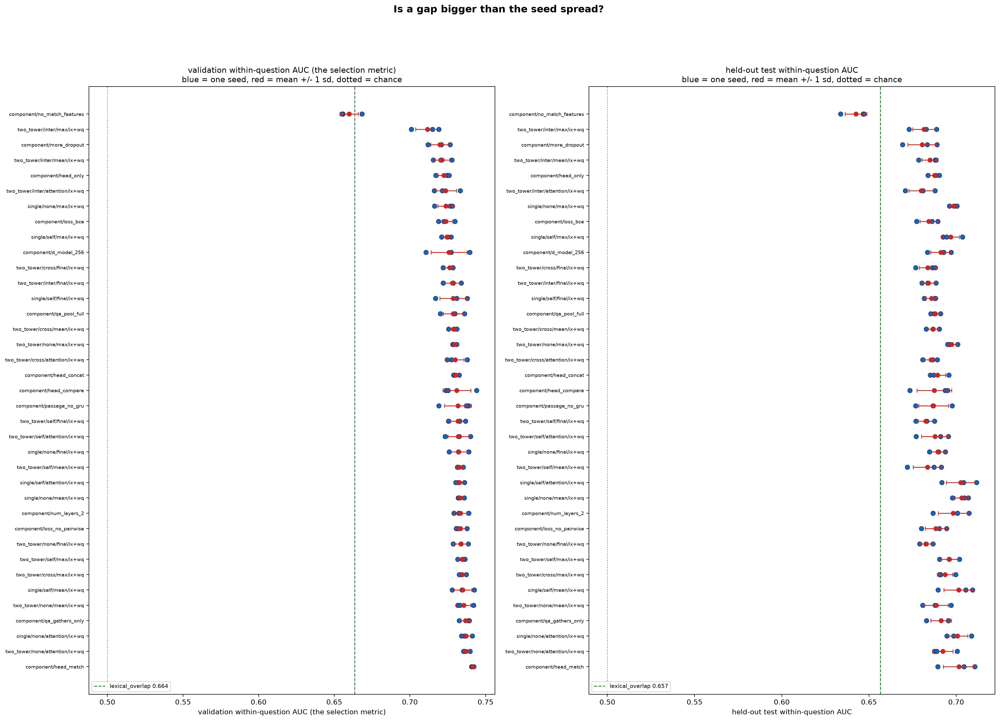

Held-out test within-question AUC, with the interval this split can actually resolve
config                             questions passages  test qAUC  95% interval (resampling passages)
----------------------------------------------------------------------------------------------------
single/none/mean/ix+wq                   942       83     0.7031                    [0.6791, 0.7281]
single/self/attention/ix+wq              942       83     0.7026                    [0.6794, 0.7279]
component/head_match                     942       83     0.7016                    [0.6781, 0.7262]
single/self/mean/ix+wq                   942       83     0.7015                    [0.6794, 0.7258]
single/none/attention/ix+wq              942       83     0.7007                    [0.6772, 0.7270]
single/none/max/ix+wq                    942       83     0.6985                    [0.6744, 0.7241]
component/num_layers_2                   942       83     0.6983                    [0.6757, 0.7219]
two_to

In [ ]:
import random
import statistics as stats
import matplotlib.pyplot as plt


def _test_metrics(label):
    model = models.get(label)
    if model is None:
        return None
    hist = experiments[label]
    return evaluate(
        model,
        test_loaders.get(label, test_loader),
        threshold=hist.get("threshold", 0.5),
        rule=hist.get("threshold_rule") or THRESHOLD_RULE,
    )


groups = {}
for label, hist in experiments.items():
    if hist.get("kind") == "screen":
        continue
    config_key = hist.get("config") or label
    groups.setdefault(config_key, []).append(label)


def _mean_of(values, fallback=float("nan")):
    filtered = [v for v in values if v is not None]
    return sum(filtered) / len(filtered) if filtered else fallback


def _sd_of(values):
    filtered = [v for v in values if v is not None]
    return stats.pstdev(filtered) if len(filtered) > 1 else 0.0


summary_rows = []
for config_name, labels_list in groups.items():
    hist_list = [experiments[l] for l in labels_list]
    test_evals = [t for t in (_test_metrics(l) for l in labels_list) if t]

    summary_rows.append({
        "config": config_name,
        "n": len(labels_list),
        "val_q_auc": _mean_of([h.get("best_val_q_auc") for h in hist_list]),
        "val_q_auc_sd": _sd_of([h.get("best_val_q_auc") for h in hist_list]),
        "val_ap": _mean_of([h.get("best_val_ap") for h in hist_list]),
        "val_q_auc_each": [h.get("best_val_q_auc") for h in hist_list],
        "test_q_auc_each": [t["q_auc"] for t in test_evals],
        "test_auc": _mean_of([t["auc"] for t in test_evals]),
        "test_ap": _mean_of([t["ap"] for t in test_evals]),
        "test_q_auc": _mean_of([t["q_auc"] for t in test_evals]),
        "test_q_ap": _mean_of([t["q_ap"] for t in test_evals]),
        "test_q_em": _mean_of([t["q_em"] for t in test_evals]),
        "test_q_f1": _mean_of([t["q_f1"] for t in test_evals]),
        "test_q_f1_sd": _sd_of([t["q_f1"] for t in test_evals]),
        "yes_rate": _mean_of([t["yes_rate"] for t in test_evals], 0.0),
    })


def _rank_key(row):
    val_key = row["val_q_auc"] if row["val_q_auc"] == row["val_q_auc"] else -1.0
    test_key = row["test_q_auc"] if row["test_q_auc"] == row["test_q_auc"] else -1.0
    return (-val_key, -test_key)


summary_rows.sort(key=_rank_key)

header = (
    f"{'config':<34}{'n':>3}{'valQAUC':>9}{'sd':>7}{'tAUC':>8}{'tAP':>8}"
    f"{'tqAUC':>8}{'tqAP':>8}{'tqEM':>8}{'tqF1':>8}{'sd':>7}{'yes%':>7}"
)
print("=" * len(header))
print("Section 4: final ablation (mean over seeds, sorted by validation within-question AUC)")
print("=" * len(header))
print(header)
print("-" * len(header))

for r in summary_rows:
    print(
        f"{r['config']:<34}{r['n']:>3}{r['val_q_auc']:>9.4f}"
        f"{r['val_q_auc_sd']:>7.4f}"
        f"{r['test_auc']:>8.4f}{r['test_ap']:>8.4f}{r['test_q_auc']:>8.4f}"
        f"{r['test_q_ap']:>8.4f}{r['test_q_em']:>8.4f}{r['test_q_f1']:>8.4f}"
        f"{r['test_q_f1_sd']:>7.4f}{r['yes_rate'] * 100:>6.1f}%"
    )
print("-" * len(header))

for name, res in baseline_results.items():
    v, t = res["val"], res["test"]
    print(
        f"{name:<34}{'-':>3}{v['q_auc']:>9.4f}{'-':>7}{t['auc']:>8.4f}"
        f"{t['ap']:>8.4f}{t['q_auc']:>8.4f}{t['q_ap']:>8.4f}"
        f"{t['q_em']:>8.4f}{t['q_f1']:>8.4f}{'-':>7}"
        f"{t['yes_rate'] * 100:>6.1f}%"
    )

if baseline_errors:
    print("-" * len(header))
    print(f"NOT RUN: {', '.join(baseline_errors)}")
    for name, err in baseline_errors.items():
        print(f"  {name:<12} {err[:96]}")
print("=" * len(header))

if summary_rows:
    best_row = summary_rows[0]
    print(
        f"Best by mean validation within-question AUC: {best_row['config']}  "
        f"({best_row['val_q_auc']:.4f} +/- {best_row['val_q_auc_sd']:.4f} over "
        f"{best_row['n']} seed(s), test qAUC {best_row['test_q_auc']:.4f})"
    )
    ties = [
        r["config"]
        for r in summary_rows[1:]
        if r["val_q_auc"] == r["val_q_auc"]
        and abs(r["val_q_auc"] - best_row["val_q_auc"]) <= max(best_row["val_q_auc_sd"], 0.002)
    ]
    if ties:
        print(f"{len(ties)} configuration(s) within 1 SD of top performer:")
        print("  " + ", ".join(ties))
    else:
        print("No other configuration within 1 SD of top performer.")

if summary_rows:
    fig, axes = plt.subplots(1, 2, figsize=(20, max(4.0, 0.34 * len(summary_rows) + 2.0)))
    panels = (
        (axes[0], "val_q_auc_each", "val", "Validation within-question AUC"),
        (axes[1], "test_q_auc_each", "test", "Held-out test within-question AUC"),
    )

    for ax, each_key, side, title in panels:
        for y_idx, row in enumerate(summary_rows):
            vals = [v for v in row[each_key] if v is not None]
            if not vals:
                continue
            ax.scatter(
                vals,
                [y_idx] * len(vals),
                s=45,
                color="#1565C0",
                zorder=3,
                edgecolor="black",
                linewidth=0.4,
            )
            ax.errorbar(
                _mean_of(vals),
                y_idx,
                xerr=_sd_of(vals),
                fmt="o",
                color="#C62828",
                markersize=6,
                capsize=3,
                linewidth=1.2,
                zorder=4,
            )

        ax.axvline(0.5, color="grey", linestyle=":", linewidth=1.2)
        if "lexical_overlap" in baseline_results:
            ref_val = baseline_results["lexical_overlap"][side]["q_auc"]
            ax.axvline(
                ref_val,
                color="#2E7D32",
                linestyle="--",
                linewidth=1.2,
                label=f"lexical_overlap {ref_val:.3f}",
            )
            ax.legend(fontsize=8, loc="lower left")

        ax.set_yticks(range(len(summary_rows)))
        ax.set_yticklabels([r["config"] for r in summary_rows], fontsize=7)
        ax.set_xlabel(title)
        ax.set_title(f"{title}\n(blue = seeds, red = mean +/- 1 SD, dotted = chance)", fontsize=11)

    fig.suptitle("Performance distribution across random seeds", fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

# Passage bootstrap statistical tests
qid_map = {}
passage_map = {}
for p, q, a, l in flat_test:
    passage_map.setdefault(p, len(passage_map))
    qid_map.setdefault((p, q), len(qid_map))

qid_to_passage = {qid_map[k]: passage_map[k[0]] for k in qid_map}
metric_cache = {}


def _cached_test_metrics(label):
    if label not in metric_cache:
        metric_cache[label] = _test_metrics(label)
    return metric_cache[label]


def _aucs_by_passage(auc_by_question):
    out = {}
    for qid, auc in (auc_by_question or {}).items():
        if qid in qid_to_passage:
            out.setdefault(qid_to_passage[qid], []).append(auc)
    return out


def _mean_interval(auc_by_question, n=2000, seed=SAMPLE_SEED):
    by_passage = _aucs_by_passage(auc_by_question)
    if len(by_passage) < 5:
        return None

    keys = sorted(by_passage)
    rng = random.Random(seed)
    sampled_means = []

    for _ in range(n):
        sampled_keys = [keys[rng.randrange(len(keys))] for _ in keys]
        vals = [v for k in sampled_keys for v in by_passage[k]]
        sampled_means.append(stats.fmean(vals))

    sampled_means.sort()
    return (
        stats.fmean(auc_by_question.values()),
        sampled_means[int(0.025 * n)],
        sampled_means[int(0.975 * n)],
        len(keys),
        len(auc_by_question),
    )


def _paired_interval(run_auc, base_auc, n=2000, seed=SAMPLE_SEED):
    shared = {}
    for qid, auc in run_auc.items():
        if qid in base_auc:
            shared.setdefault(qid_to_passage[qid], []).append((auc, base_auc[qid]))
    if len(shared) < 5:
        return None

    keys = sorted(shared)
    rng = random.Random(seed)
    sampled_gaps = []

    for _ in range(n):
        sampled_keys = [keys[rng.randrange(len(keys))] for _ in keys]
        rows = [r for k in sampled_keys for r in shared[k]]
        diff = stats.fmean([a for a, _ in rows]) - stats.fmean([b for _, b in rows])
        sampled_gaps.append(diff)

    sampled_gaps.sort()
    return (
        stats.fmean(sampled_gaps),
        sampled_gaps[int(0.025 * n)],
        sampled_gaps[int(0.975 * n)],
        sum(g > 0 for g in sampled_gaps) / n,
        len(keys),
    )


config_auc_map = {}
for config_name, labels_list in groups.items():
    per_run = [(_cached_test_metrics(l) or {}).get("q_auc_by_question") for l in labels_list]
    per_run = [a for a in per_run if a]
    if not per_run:
        continue
    shared_qids = (
        set.intersection(*(set(a) for a in per_run)) if len(per_run) > 1 else set(per_run[0])
    )
    config_auc_map[config_name] = {
        q: stats.fmean([a[q] for a in per_run]) for q in shared_qids
    }

header = (
    f"{'config':<34}{'questions':>10}{'passages':>9}{'test qAUC':>11}"
    f"{'95% interval (resampling passages)':>36}"
)
print("=" * len(header))
print("Held-out test within-question AUC (passage bootstrap 95% CI)")
print("=" * len(header))
print(header)
print("-" * len(header))

for config_name, auc_dict in sorted(
    config_auc_map.items(), key=lambda kv: -stats.fmean(kv[1].values())
):
    ci = _mean_interval(auc_dict)
    if ci is None:
        continue
    mean_val, lo, hi, n_passages, n_q = ci
    print(f"{config_name:<34}{n_q:>10}{n_passages:>9}{mean_val:>11.4f}{f'[{lo:.4f}, {hi:.4f}]':>36}")

for name, res in baseline_results.items():
    ci = _mean_interval(res["test"].get("q_auc_by_question"))
    if ci is None:
        continue
    mean_val, lo, hi, n_passages, n_q = ci
    print(f"{name:<34}{n_q:>10}{n_passages:>9}{mean_val:>11.4f}{f'[{lo:.4f}, {hi:.4f}]':>36}")
print("-" * len(header))

if config_auc_map and baseline_results:
    best_config_name = max(config_auc_map, key=lambda c: stats.fmean(config_auc_map[c].values()))
    run_auc_dict = config_auc_map[best_config_name]
    header = (
        f"{'baseline':<24}{'tqAUC':>9}{'gap':>9}{'95% interval of the gap':>28}"
        f"{'P(model better)':>17}   verdict"
    )
    print("=" * len(header))
    print(f"Paired comparison on shared passages ({best_config_name})")
    print("=" * len(header))
    print(header)
    print("-" * len(header))

    for name, res in baseline_results.items():
        paired_res = _paired_interval(run_auc_dict, res["test"].get("q_auc_by_question") or {})
        if paired_res is None:
            continue
        gap, lo, hi, p_val, _ = paired_res
        verdict = (
            "separated"
            if lo > 0
            else "SEPARATED, MODEL WORSE"
            if hi < 0
            else "NOT separated"
        )
        print(
            f"{name:<24}{res['test']['q_auc']:>9.4f}{gap:>+9.4f}"
            f"{f'[{lo:+.4f}, {hi:+.4f}]':>28}{p_val:>17.2f}   {verdict}"
        )
    print("-" * len(header))

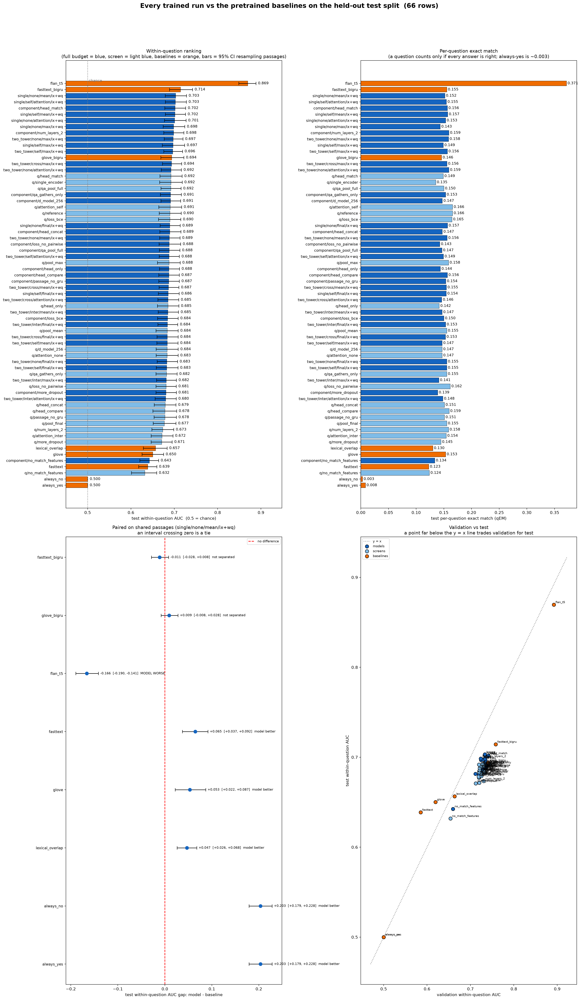

Summary (test split)
  flan_t5                           baseline  qAUC=0.8695 [0.8488, 0.8882]   qEM=0.3715
  fasttext_bigru                    baseline  qAUC=0.7144 [0.6887, 0.7419]   qEM=0.1553
  single/none/mean/ix+wq            model     qAUC=0.7031 [0.6791, 0.7281]   qEM=0.1518
  single/self/attention/ix+wq       model     qAUC=0.7026 [0.6794, 0.7279]   qEM=0.1546
  component/head_match              model     qAUC=0.7016 [0.6781, 0.7262]   qEM=0.1563
  single/self/mean/ix+wq            model     qAUC=0.7015 [0.6794, 0.7258]   qEM=0.1570
  single/none/attention/ix+wq       model     qAUC=0.7007 [0.6772, 0.7270]   qEM=0.1532
  single/none/max/ix+wq             model     qAUC=0.6985 [0.6744, 0.7241]   qEM=0.1434
  component/num_layers_2            model     qAUC=0.6983 [0.6757, 0.7219]   qEM=0.1591
  two_tower/none/max/ix+wq          model     qAUC=0.6974 [0.6767, 0.7199]   qEM=0.1584
  single/self/max/ix+wq             model     qAUC=0.6969 [0.6723, 0.7237]   qEM=0.1490
  two_tower

In [ ]:
import random
import statistics as stats
import matplotlib.pyplot as plt
import numpy as np

INCLUDE_SCREEN_RUNS = True

try:
    base_results = baseline_results
except NameError:
    base_results = {}

if not experiments or not base_results:
    print("Run section 3 and the baselines cell first: experiments and baseline_results are required.")
else:
    cmp_passage = {}
    cmp_qid = {}
    for p, q, a, l in flat_test:
        cmp_passage.setdefault(p, len(cmp_passage))
        cmp_qid.setdefault((p, q), len(cmp_qid))
    cmp_q2p = {cmp_qid[k]: cmp_passage[k[0]] for k in cmp_qid}

    def _cmp_by_passage(auc_by_q):
        out = {}
        for q, auc in (auc_by_q or {}).items():
            if q in cmp_q2p:
                out.setdefault(cmp_q2p[q], []).append(auc)
        return out

    def _cmp_ci(auc_by_q, n=2000, seed=SAMPLE_SEED):
        by_p = _cmp_by_passage(auc_by_q)
        if len(by_p) < 5:
            return None
        keys = sorted(by_p)
        rng = random.Random(seed)
        means = []
        for _ in range(n):
            vals = [v for k in (keys[rng.randrange(len(keys))] for _ in keys) for v in by_p[k]]
            means.append(stats.fmean(vals))
        means.sort()
        return (stats.fmean(auc_by_q.values()), means[int(0.025 * n)], means[int(0.975 * n)])

    def _cmp_paired(run_auc, base_auc, n=2000, seed=SAMPLE_SEED):
        shared = {}
        for q, auc in run_auc.items():
            if q in base_auc:
                shared.setdefault(cmp_q2p[q], []).append((auc, base_auc[q]))
        if len(shared) < 5:
            return None
        keys = sorted(shared)
        rng = random.Random(seed)
        gaps = []
        for _ in range(n):
            rows = [r for k in (keys[rng.randrange(len(keys))] for _ in keys) for r in shared[k]]
            diff = stats.fmean([a for a, _ in rows]) - stats.fmean([b for _, b in rows])
            gaps.append(diff)
        gaps.sort()
        return (stats.fmean(gaps), gaps[int(0.025 * n)], gaps[int(0.975 * n)])

    cmp_configs = {}
    cmp_kind = {}
    for label, hist in sorted(experiments.items()):
        is_screen = hist.get("kind") == "screen"
        if is_screen and not INCLUDE_SCREEN_RUNS:
            continue
        key = hist.get("config") or label
        cmp_configs.setdefault(key, []).append(label)
        cmp_kind[key] = "screen" if is_screen else "model"

    cmp_qem = {}
    cmp_qf1 = {}
    cmp_auc_q = {}
    cmp_val = {}

    for config_key, labels_list in cmp_configs.items():
        eval_metrics_list = [
            evaluate(
                models[l],
                test_loaders.get(l, test_loader),
                threshold=experiments[l].get("threshold", 0.5),
                rule=experiments[l].get("threshold_rule") or THRESHOLD_RULE,
            )
            for l in labels_list
        ]
        cmp_qem[config_key] = stats.fmean([m["q_em"] for m in eval_metrics_list])
        cmp_qf1[config_key] = stats.fmean([m["q_f1"] for m in eval_metrics_list])
        cmp_val[config_key] = stats.fmean(
            [
                h.get("best_val_q_auc") or h.get("best_val_ap") or float("nan")
                for h in (experiments[l] for l in labels_list)
            ]
        )

        per_run_aucs = [m["q_auc_by_question"] for m in eval_metrics_list if m.get("q_auc_by_question")]
        if per_run_aucs:
            shared_qids = (
                set.intersection(*(set(a) for a in per_run_aucs))
                if len(per_run_aucs) > 1
                else set(per_run_aucs[0])
            )
            cmp_auc_q[config_key] = {
                q: stats.fmean([a[q] for a in per_run_aucs]) for q in shared_qids
            }

    def _cmp_entry(name, kind, auc_by_q, qem, val):
        ci = _cmp_ci(auc_by_q)
        if ci is None:
            return None
        return {
            "name": name,
            "kind": kind,
            "auc": ci[0],
            "lo": ci[1],
            "hi": ci[2],
            "qem": qem,
            "val": val,
        }

    entries = []
    for config_key, auc_dict in cmp_auc_q.items():
        e = _cmp_entry(
            config_key,
            cmp_kind[config_key],
            auc_dict,
            cmp_qem[config_key],
            cmp_val[config_key],
        )
        if e:
            entries.append(e)

    base_auc_q = {}
    for name, res in base_results.items():
        base_auc_q[name] = res["test"].get("q_auc_by_question") or {}
        e = _cmp_entry(
            name,
            "baseline",
            base_auc_q[name],
            res["test"]["q_em"],
            res["val"]["q_auc"],
        )
        if e:
            entries.append(e)

    entries.sort(key=lambda e: e["auc"])

    colours = {"model": "#1565C0", "screen": "#7FBCE8", "baseline": "#EF6C00"}
    names = [e["name"] for e in entries]
    ypos = np.arange(len(entries))

    fig, axes = plt.subplots(2, 2, figsize=(20, max(9.0, 0.45 * len(entries) + 5.0)))
    fig.suptitle(
        f"Model vs Pretrained Baselines on Held-Out Test Split ({len(entries)} rows)",
        fontsize=16,
        fontweight="bold",
    )

    # 1. Within-question AUC
    ax = axes[0][0]
    ax.barh(
        ypos,
        [e["auc"] for e in entries],
        color=[colours[e["kind"]] for e in entries],
        edgecolor="black",
        linewidth=0.5,
    )
    ax.errorbar(
        [e["auc"] for e in entries],
        ypos,
        xerr=[
            [e["auc"] - e["lo"] for e in entries],
            [e["hi"] - e["auc"] for e in entries],
        ],
        fmt="none",
        ecolor="black",
        capsize=4,
        linewidth=1.2,
    )
    ax.axvline(0.5, color="grey", linestyle=":", linewidth=1.5)
    ax.text(0.5, len(entries) - 0.3, " chance", color="grey", fontsize=9, va="top")
    for y, e in zip(ypos, entries):
        ax.text(e["hi"] + 0.005, y, f"{e['auc']:.3f}", va="center", fontsize=9)
    ax.set_yticks(ypos)
    ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel("Test within-question AUC (0.5 = chance)")
    ax.set_title("Within-question ranking (95% CI resampling passages)", fontsize=11)
    ax.set_xlim(0.45, min(1.0, max(e["hi"] for e in entries) + 0.06))

    # 2. Per-question exact match
    ax = axes[0][1]
    ax.barh(
        ypos,
        [e["qem"] for e in entries],
        color=[colours[e["kind"]] for e in entries],
        edgecolor="black",
        linewidth=0.5,
    )
    for y, e in zip(ypos, entries):
        ax.text(e["qem"] + 0.002, y, f"{e['qem']:.3f}", va="center", fontsize=9)
    ax.set_yticks(ypos)
    ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel("Test per-question exact match (qEM)")
    ax.set_title("Per-question exact match", fontsize=11)

    # 3. Paired gap against each baseline
    ax = axes[1][0]
    model_entries = [e for e in entries if e["kind"] != "baseline"]
    if model_entries and base_auc_q:
        best_entry = max(model_entries, key=lambda e: e["auc"])
        best_run_auc = cmp_auc_q[best_entry["name"]]
        rows_y = []
        row_labels = []
        for name in base_results:
            p = _cmp_paired(best_run_auc, base_auc_q[name])
            if p is None:
                continue
            rows_y.append(p)
            row_labels.append(name)

        if rows_y:
            yy = np.arange(len(rows_y))
            ax.errorbar(
                [p[0] for p in rows_y],
                yy,
                xerr=[
                    [p[0] - p[1] for p in rows_y],
                    [p[2] - p[0] for p in rows_y],
                ],
                fmt="o",
                color="#1565C0",
                ecolor="black",
                capsize=4,
                markersize=8,
                linewidth=1.2,
            )
            ax.axvline(0.0, color="red", linestyle="--", linewidth=1.5, label="no difference")
            for y, p in zip(yy, rows_y):
                verdict = (
                    "model better"
                    if p[1] > 0
                    else "MODEL WORSE"
                    if p[2] < 0
                    else "not separated"
                )
                ax.text(
                    p[2] + 0.004,
                    y,
                    f"{p[0]:+.3f}  [{p[1]:+.3f}, {p[2]:+.3f}]  {verdict}",
                    va="center",
                    fontsize=8,
                )
            ax.set_yticks(yy)
            ax.set_yticklabels(row_labels, fontsize=9)
            ax.set_xlabel("Test within-question AUC gap: model - baseline")
            ax.set_title(f"Paired on shared passages ({best_entry['name']})", fontsize=11)
            ax.legend(fontsize=8)

    # 4. Validation vs test
    ax = axes[1][1]
    lims = [
        min(e["val"] for e in entries) - 0.03,
        max(max(e["auc"] for e in entries), max(e["val"] for e in entries)) + 0.03,
    ]
    ax.plot(lims, lims, color="grey", linestyle=":", linewidth=1.5, label="y = x")
    for kind_name in ("model", "screen", "baseline"):
        sub = [e for e in entries if e["kind"] == kind_name]
        if sub:
            ax.scatter(
                [e["val"] for e in sub],
                [e["auc"] for e in sub],
                s=70,
                c=colours[kind_name],
                edgecolor="black",
                label=f"{kind_name}s",
                zorder=3,
            )
    for e in entries:
        ax.annotate(
            e["name"].split("/")[-1],
            (e["val"], e["auc"]),
            fontsize=7,
            xytext=(4, 4),
            textcoords="offset points",
        )
    ax.set_xlabel("Validation within-question AUC")
    ax.set_ylabel("Test within-question AUC")
    ax.set_title("Validation vs Test Generalization", fontsize=11)
    ax.legend(fontsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    print("=" * 100)
    print("Summary (held-out test split)")
    print("=" * 100)
    for e in sorted(entries, key=lambda item: -item["auc"]):
        print(
            f"  {e['name']:<34}{e['kind']:<10}"
            f"qAUC={e['auc']:.4f} [{e['lo']:.4f}, {e['hi']:.4f}]   "
            f"qEM={e['qem']:.4f}"
        )
    print("=" * 100)

    if model_entries and base_auc_q:
        best_entry = max(model_entries, key=lambda e: e["auc"])
        worse_baselines = [
            n
            for n in base_results
            if (_cmp_paired(cmp_auc_q[best_entry["name"]], base_auc_q[n]) or (0, 0, 0))[2] < 0
        ]
        tied_baselines = [
            n
            for n in base_results
            if (p := _cmp_paired(cmp_auc_q[best_entry["name"]], base_auc_q[n]))
            and p[1] <= 0 <= p[2]
        ]
        if worse_baselines:
            print(f"Top model ({best_entry['name']}) trails baselines: {', '.join(worse_baselines)}.")
        if tied_baselines:
            print(f"Top model ({best_entry['name']}) statistically tied with: {', '.join(tied_baselines)}.")
        if not worse_baselines and not tied_baselines:
            print(f"Top model ({best_entry['name']}) significantly exceeds all baselines.")

In [ ]:
if SAVE_RESULTS:
    export_results(RESULTS_DIR, experiments, models, baseline_results, baseline_errors)
else:
    print(
        f"SAVE_RESULTS is disabled. Set SAVE_RESULTS=True and re-run to export results to {RESULTS_DIR}/."
    )

Exported 132 run(s), 132 model(s) and 8 baseline(s) to /marimo/results_export/
  experiments.json  baselines.json  manifest.json  weights/ (132 file(s))
  Set LOAD_RESULTS = True in the hyperparameters cell to read it back.
